# ¿Cuánto aviso nos da un río? · 05 — Estaciones aguas arriba: ¿cuánto aportan al pronóstico?

**Curso:** Ciencia de Datos Ambientales (CDA) · Universidad de Ingeniería y Tecnología (UTEC) · Proyecto Integrador

**Equipo:** 

- Luis Angel Cupe Espinoza
- Yely Lanasca Justiniano 
- Lia Kim Alcantara Tineo 
- Mayra Madelyn Marzano Mejia 
- María Fernanda Torres Carbajal 

**Protocolo:** común a todo el estudio (`comun.py` e `integrado.py`; identificado como `v4` en el código y en las salidas). La fecha de ejecución y las versiones de software se imprimen en la celda de configuración.

**Lugar en el estudio:** este cuaderno responde la pregunta **P3**: cuánto aporta el caudal observado de las estaciones aguas arriba **inmediatas** —San Regis (SR) y Requena (RQ) en Tamshiyacu; Cirato en Racarumi, de forma exploratoria— al pronóstico, con los **seis modelos** del estudio: Q, Q+SR, Q+RQ y Q+SR+RQ, con las fuentes externas **hasta t** y **hasta t−1**, en las mismas filas. La lluvia se estudia en el 06 y Chronos-2 en el 07; la comparación integrada y la selección final del proyecto están en el **08**, que reutiliza estos ajustes.

**Sobre el periodo de prueba:** las reglas se fijaron antes de la evaluación final (sección 0.3), pero el periodo de prueba (desde 2016-01) se consultó durante el desarrollo del proyecto, también con estas estaciones: no es una prueba ciega.

---

## 0. Objetivo y decisiones de diseño

### 0.1 Pregunta
> **¿Mejora el pronóstico diario de la magnitud del caudal, su horizonte útil y su anticipación de crecidas si además del caudal de la propia estación se usa el de las estaciones aguas arriba? ¿Depende de qué día llega ese dato y de qué modelo lo usa?**

Una estación aguas arriba solo puede **adelantar** información si el agua tarda al menos un día en llegar (la resolución de los datos). Por eso el cuaderno mide primero el **desfase de máxima asociación** entre las variaciones diarias (un indicio estadístico, no una medición del tránsito) y después la **ganancia** en un experimento controlado con los seis modelos.

| Estación objetivo | Estaciones aguas arriba inmediatas | Qué permite el registro |
|---|---|---|
| Tamshiyacu (Amazonas, ~720 000 km²) | San Regis (Marañón, 50 % del área) y Requena (Ucayali, 48 %) | Experimento completo: registros observados desde 1996–1998; Requena termina en 2020-03 |
| Racarumi (Chancay-Lambayeque, 2 363 km²) | Cirato (68 % del área) | Solo análisis exploratorio: 13 meses con fechas confiables |

### 0.2 Decisión sobre Cirato (fijada antes de ejecutar)
El EDA encontró que el registro de Cirato entre 2008-11 y 2022-07 tiene las **fechas corridas**: el desfase crece cerca de un día por año (0 en 2009, 12 en 2021–2022). Había tres caminos:

| Opción | Por qué no se usa como análisis principal |
|---|---|
| **Realinear año a año** con el desfase estimado | El desfase se estima por año con resolución de un día y cambia ~1 día dentro de cada año. La incertidumbre de la realineación (±1 día) es del mismo tamaño que la señal que se quiere medir (el desfase Cirato → Racarumi, menor a 1 día según el EDA). Un adelanto "encontrado" con la serie realineada no se podría distinguir de un error de alineación. Además Cirato empieza en 2008-11: no hay datos de Cirato en el entrenamiento (hasta 2008). |
| **Usar el caudal simulado** de Cirato | El simulado sale del mismo forzamiento de lluvia PISCO y de un mapeo de cuantiles contra el observado (EDA 2.6). No es una medición independiente del río: mediría el aporte de la lluvia, no el de una estación aguas arriba. |
| **Excluir el tramo con fechas corridas** (elegida) | Respeta la regla del EDA (3.3). Cirato se analiza solo en 2022-08-01 a 2023-08-31, como análisis **exploratorio** (desfase de máxima asociación y una prueba de 1–3 días con evaluación retrospectiva por bloques mensuales). |

### 0.3 Protocolo del experimento en Tamshiyacu (fijado antes de ejecutar)
| Paso | Decisión |
|---|---|
| Configuraciones | **Q**: caudal local (nivel de hoy y 29 cambios diarios) y calendario, como en los modelos base (01–02). **Q+SR**, **Q+RQ**, **Q+SR+RQ**: cada estación agregada entra con la misma forma que la propia (ventana t − 29 … t, con las reglas de vacíos ≤ 3 días y sin escalones de nivel dentro de la ventana). Cada una con las fuentes externas **hasta t** y **hasta t−1** (ventana desplazada un día); el caudal local siempre llega hasta t. |
| Mismas filas | Todas las configuraciones se entrenan y validan con **exactamente las mismas emisiones** (`entradas.FILAS['Tamshiyacu (con San Regis)']`): las que tienen válidas las ventanas de San Regis (t y t−1) y, en entrenamiento y validación, también las de Requena (t y t−1). Son las mismas filas que usa el 08, que así reutiliza estos ajustes. |
| División | Entrenamiento hasta 2008 (desde 1998-10, por el inicio de San Regis); validación 2009–2015 (Duan 2009–2011, selección 2012–2015); prueba 2016–fin; la LSTM detiene con 2005–2008. |
| Dos periodos de prueba | **Con San Regis (prueba 2016-01 a 2025-12)**: Q y Q+SR. **Común con Requena (prueba 2016-01 a 2020-03)**, Requena termina:  las cuatro configuraciones, todas evaluadas en las mismas emisiones (Requena válida hasta t y hasta t−1). Nunca se comparan métricas de periodos distintos. |
| Modelos | Los seis modelos del estudio con sus mallas, semillas y estrategias (`entradas.ajustar`, caché con identidad completa). |
| Selección para la magnitud | En 2012–2015 con la regla de selección del estudio (mayor NSE medio; IC 90 % por bootstrap pareado de meses; la más simple entre el mejor y sus equivalentes: menos fuentes y, después, el modelo más simple), por escenario de disponibilidad (**mismo día**: fuentes hasta t; **un día de retraso**: hasta t−1) y por periodo: con San Regis, entre Q y Q+SR; con Requena, entre las cuatro. |
| Avisos | Reglas del cuaderno 04 solo si hay eventos para calibrar y evaluar. Se cuentan los cruces evaluables de cada bloque; con 3 cruces en la prueba y ninguno en el periodo con Requena **no se selecciona** un sistema de avisos (sección 8). |
| Medidas de prueba | NSE por horizonte, horizonte útil (cota 95 % del bootstrap conjunto por meses), **ganancia G = 1 − MSE(con)/MSE(sin)** del mismo modelo por bandas (1–3, 4–7, 8–15, 16–30 días) con IC 90 % por bootstrap pareado de meses, efecto del método, caudales altos (descriptivo) y muestra extendida. Climatología de referencia hasta 2015. |

### 0.4 Hipótesis de este cuaderno
- **HA1:** cada estación aguas arriba se adelanta a la de destino al menos un día (desfase de máxima asociación ≥ 1 día).
- **HA2:** agregarla reduce el error de la magnitud, sobre todo en los primeros días, con todos los modelos.
- **HA3:** el beneficio se mantiene, al menos en parte, si el dato llega un día tarde (t−1).

---
## 1. Configuración
Librerías, semillas y rutas relativas. `aguas_arriba.py` carga las estaciones aguas arriba (reglas del EDA), arma sus ventanas y calcula el desfase de máxima asociación; `entradas.py`, las entradas de cada configuración y el ajuste de los seis modelos con caché; `integrado.py`, el protocolo común de comparación (validación, selección, prueba y avisos).

In [1]:
import os, sys, json, time, warnings, platform
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, xgboost, torch

import comun as C
import aguas_arriba as A
import entradas as EN
import integrado as I

%matplotlib inline
warnings.filterwarnings('ignore')
np.random.seed(C.SEMILLA)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

RAPIDO = os.environ.get('CDA_RAPIDO') == '1'          # solo para probar el código: mallas mínimas, una semilla
if RAPIDO:
    C.MALLAS = {k: {kk: vv[:1] for kk, vv in v.items()} for k, v in C.MALLAS.items()}
    C.SEMILLAS = C.SEMILLAS[:1]
B = 50 if RAPIDO else 1000

RUTA_SAL = C.ruta_salidas() / 'aguas_arriba'          # modo rápido: salidas_rapido/ (nunca se mezcla con la ejecución final)
PREVIAS = {k: C.verificar_resumen(C.ruta_salidas() / k / 'resumen.json') for k in ['tamshiyacu', 'racarumi']}
RUTA_FIG, RUTA_TAB = RUTA_SAL / 'figuras', RUTA_SAL / 'tablas'
for r in (RUTA_FIG, RUTA_TAB):
    r.mkdir(parents=True, exist_ok=True)

L, H = C.L_VENTANA, len(C.HORIZONTES)
MODELOS = I.MODELOS
SR, RQ = EN.SR, EN.RQ
COLV = {'Q': '#444444', 'Q+SR': '#1f77b4', 'Q+RQ': '#2ca02c', 'Q+SR+RQ': '#d62728', '+ San Regis': '#1f77b4', '+ Requena': '#2ca02c'}
FUENTE = 'Fuente: CAMELS-PE v1.0.1 (SENAMHI), caudal observado depurado del EDA'
T_INICIO = time.time()

print(f"Ejecutado: {datetime.now():%Y-%m-%d %H:%M} | protocolo {C.VERSION} | modo rápido: {RAPIDO}")
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | torch {torch.__version__}")

Ejecutado: 2026-11-22 19:19 | protocolo v4 | modo rápido: False
Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 3.1.2 | torch 2.14.1+cu130


---
## 2. Datos y filas del experimento (Tamshiyacu)
Caudal observado depurado de Tamshiyacu, San Regis y Requena con las reglas del EDA (errores eliminados en 4.3, meses de Requena excluidos por inconsistencia de balance en 4.4). En cada estación, ε y el umbral de escalones de nivel se fijan **con el entrenamiento** (hasta 2008), como en los modelos base (01–02), y se comprueba que la ventana aguas arriba de cada emisión termina en el día t (sin información futura).

In [2]:
qT, infoT = C.cargar_serie('Tamshiyacu')
EPS_T, ESC_T = C.eps_entrenamiento(qT), C.escalones(qT)
P95 = float(np.nanpercentile(qT.loc[:C.FIN_ENTRENAMIENTO], 95))
m_tot = C.construir_muestras(qT, L=L, H=H, esc=ESC_T, eps=EPS_T)
p_tot = C.particion(m_tot)

ARR, filas_inv = {}, []
filas_inv.append({'estación': 'Tamshiyacu', 'río': 'Amazonas', 'rol': 'objetivo', 'área (km²)': infoT['area'],
                  'registro': f"{infoT['inicio']:%Y-%m-%d} a {infoT['fin']:%Y-%m-%d}", 'vacíos (%)': infoT['vacios'],
                  'escalones (umbral de entrenamiento)': len(ESC_T), 'excluido por el EDA': f"{infoT['n_eliminados']} días",
                  'ε (m³/s)': EPS_T})
for n in ['San Regis', 'Requena']:
    q, inf = A.cargar_arriba(n)
    eps, esc = C.eps_entrenamiento(q), C.escalones(q)
    vent, ok = A.ventanas_entrada(q, m_tot.fechas, L, eps, esc)
    zt = np.log(q.reindex(m_tot.fechas) + eps).to_numpy()
    assert np.allclose(vent[ok, -1], zt[ok]), f'{n}: la ventana de entrada debe terminar en el día de emisión t'
    ARR[n] = dict(q=q, info=inf, eps=eps, esc=esc, vent=vent, ok=ok)
    filas_inv.append({'estación': n, 'río': A.ARRIBA[n]['rio'], 'rol': 'aguas arriba', 'área (km²)': inf['area'],
                      'registro': f"{inf['inicio']:%Y-%m-%d} a {inf['fin']:%Y-%m-%d}", 'vacíos (%)': inf['vacios'],
                      'escalones (umbral de entrenamiento)': f"{len(esc)}" + (f" ({esc.min():%Y}–{esc.max():%Y})" if len(esc) else ''),
                      'excluido por el EDA': f"{inf['n_eliminados']} días" + (f" + meses {', '.join(inf['meses_excluidos'])}" if inf['meses_excluidos'] else ''),
                      'ε (m³/s)': eps})
inv = pd.DataFrame(filas_inv).set_index('estación')
inv.to_csv(RUTA_TAB / 'tabla_estaciones.csv')
print(f"P95 de Tamshiyacu (entrenamiento) = {P95:,.0f} m³/s")
inv.round(2)

P95 de Tamshiyacu (entrenamiento) = 47,603 m³/s


,río,rol,área (km²),registro,vacíos (%),escalones (umbral de entrenamiento),excluido por el EDA,ε (m³/s)
estación,,,,,,,,
Tamshiyacu,Amazonas,objetivo,719664.67,1984-09-01 a 2025-12-31,0.46,41,0 días,301.46
San Regis,Marañón,aguas arriba,360046.76,1998-09-01 a 2025-12-31,4.57,17 (1999–2024),0 días,169.35
Requena,Ucayali,aguas arriba,347946.09,1996-07-01 a 2020-03-31,3.63,1 (2007–2007),"11 días + meses 2017-06, 2017-07, 2017-08",119.10


**Interpretación:**
- **San Regis** (Marañón) y **Requena** (Ucayali) drenan juntas el 98 % del área de Tamshiyacu (360 046 y 347 946 de 719 665 km²).
- **San Regis:** con el umbral de entrenamiento se detectan sus **17 escalones de nivel** (1999–2024), los mismos del EDA. Las emisiones cuya ventana de 30 días cruza uno de ellos quedan fuera.
- **Requena:** se eliminan los 11 días erróneos de agosto de 2017 y los meses **2017-06 a 2017-08** (inconsistencia de balance, EDA 4.4). Con el umbral fijado en el entrenamiento, el único escalón detectado es 2007-10-01. El del EDA (2017-09-01) cae dentro de los meses ya excluidos.
- **ε de cada estación:** 1 % de su caudal medio de entrenamiento, como en los modelos base (01–02) (169 m³/s en San Regis y 119 m³/s en Requena).

### 2.1 Filas comunes y periodos de prueba
El experimento (`entradas.DISENO_ARRIBA`, `integrado.cargar`) usa las filas en que las ventanas de San Regis son válidas en t y en t−1 y, en entrenamiento y validación, también las de Requena en t y t−1. La prueba con San Regis (2016-01 a 2025-12) se separa de la prueba común con Requena (2016-01 a 2020-03), y el número de emisiones se compara con el de los modelos base del cuaderno 02 (columna «emisiones v4»).

In [3]:
x = I.cargar('Tamshiyacu', EN.DISENO_ARRIBA)
m, p, VC = x.m, x.p, x.VC
ie, iv = p['ent'], p['val']
IP_SR = p['pru']                                         # prueba con San Regis (2016-01 a 2025-12)
# Prueba común con Requena (2016-01 a 2020-03): emisiones con la ventana de Requena válida en t y en t−1 (las mismas para
# las cuatro configuraciones y los dos escenarios; Requena hasta t y hasta t−1 difieren en 5 emisiones cada una)
IP_RQ = I.comunes(*[x.D[k].ip for k in x.D if RQ in k[0]])
DIF_RQ = {I.etiqueta(*k): len(np.setdiff1d(x.D[k].ip, IP_RQ)) for k in x.D if RQ in k[0]}
assert all(np.array_equal(x.D[k].ip, IP_SR) for k in x.D if RQ not in k[0])
print(f'Prueba común con Requena: {len(IP_RQ)} emisiones; emisiones propias de cada configuración fuera de ella: {DIF_RQ}')
# Las etiquetas de los periodos de prueba se construyen con los meses reales de sus emisiones (las mismas del 08)
ALC_SR = I.etiqueta_periodo(x, IP_SR, 'con San Regis')            # 'con San Regis (prueba 2016-01 a 2025-12)'
ALC_RQ = I.etiqueta_periodo(x, IP_RQ, 'común con Requena')        # 'común con Requena (prueba 2016-01 a 2020-03)'
print(ALC_SR, '|', ALC_RQ)
EN_C = np.isin(IP_SR, IP_RQ)
def rango(idx):
    f = m.fechas[idx]
    return f"{f.min():%Y-%m-%d} a {f.max():%Y-%m-%d}"
div = pd.DataFrame([
    {'bloque': 'Entrenamiento', 'emisiones': len(ie), 'periodo': rango(ie), 'emisiones v4': len(p_tot['ent'])},
    {'bloque': 'Validación: calibración (Duan)', 'emisiones': len(VC.cal), 'periodo': rango(iv[VC.cal]), 'emisiones v4': np.nan},
    {'bloque': 'Validación: selección', 'emisiones': len(VC.sel), 'periodo': rango(iv[VC.sel]), 'emisiones v4': np.nan},
    {'bloque': 'Validación (total)', 'emisiones': len(iv), 'periodo': rango(iv), 'emisiones v4': len(p_tot['val'])},
    {'bloque': 'Prueba con San Regis (Q y Q+SR)', 'emisiones': len(IP_SR), 'periodo': rango(IP_SR), 'emisiones v4': len(p_tot['pru'])},
    {'bloque': 'Prueba común con Requena (las cuatro configuraciones)', 'emisiones': len(IP_RQ), 'periodo': rango(IP_RQ), 'emisiones v4': np.nan},
]).set_index('bloque')
div.to_csv(RUTA_TAB / 'tabla_division.csv')
div

Prueba común con Requena: 1093 emisiones; emisiones propias de cada configuración fuera de ella: {'Q+RQ': 5, 'Q+RQ (t−1)': 5, 'Q+SR+RQ': 5, 'Q+SR+RQ (t−1)': 5}
con San Regis (prueba 2016-01 a 2025-12) | común con Requena (prueba 2016-01 a 2020-03)


,emisiones,periodo,emisiones v4
bloque,,,
Entrenamiento,2847,1998-10-01 a 2008-12-01,6904.0
Validación: calibración (Duan),760,2009-01-31 a 2011-12-01,NaN
Validación: selección,1138,2012-01-01 a 2015-12-01,NaN
Validación (total),1928,2009-01-31 a 2015-12-01,2025.0
Prueba con San Regis (Q y Q+SR),2806,2016-01-01 a 2025-12-01,3252.0
Prueba común con Requena (las cuatro configuraciones),1093,2016-01-01 a 2020-03-31,NaN


**Interpretación:**
- **Entrenamiento: 2 847 emisiones (1998-10 a 2008-12),** el 41 % de las 6 904 del cuaderno 02: el inicio de San Regis acorta la historia. Todas las configuraciones (también Q) se reentrenan con esas mismas filas para que la comparación sea justa.
- **Validación: 1 928 emisiones** (cuaderno 02: 2 025): 760 para la corrección de Duan (2009–2011) y 1 138 para la selección (2012–2015). Son las emisiones con San Regis y Requena válidas en t y en t−1, así que **todas las configuraciones se eligen en las mismas fechas**.
- **Prueba con San Regis: 2 806 emisiones (2016-01 a 2025-12),** el 86 % de la prueba del cuaderno 02. Aquí solo compiten Q y Q+SR.
- **Prueba común con Requena: 1 093 emisiones (2016-01 a 2020-03).** Requena deja de medir en 2020-03; además se exige su ventana válida en t y en t−1 para que las cuatro configuraciones y los dos escenarios se evalúen en las mismas emisiones (cada configuración tenía 5 emisiones propias fuera de este conjunto).
  - Le falta casi todo 2019: **las dos estaciones aguas arriba tienen vacíos que empiezan justo en la crecida de 2019.** San Regis no tiene dato desde el 2019-04-07 (el día del pico de Tamshiyacu) durante 147 días; Requena, desde el 2019-03-05 durante 180 días.

**Figura 1.** (a) Caudal observado depurado de las tres estaciones con los bloques temporales; los triángulos son escalones de nivel y el sombreado gris, los meses de Requena excluidos por el EDA. (b) Emisiones usadas en el experimento por bloque.

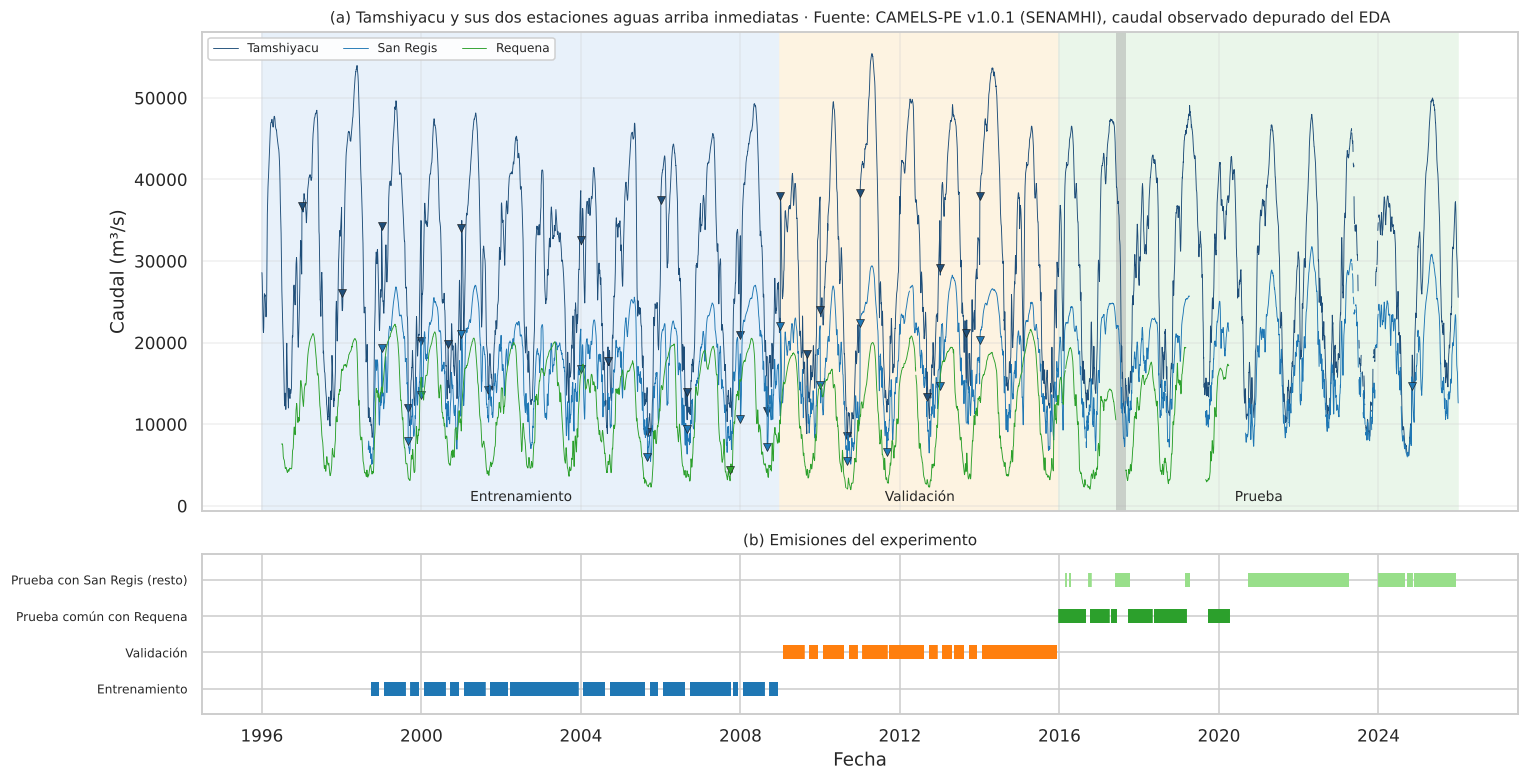

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(14, 7.2), gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
for n, q, col in [('Tamshiyacu', qT, '#1f4e79'), ('San Regis', ARR['San Regis']['q'], '#1f77b4'), ('Requena', ARR['Requena']['q'], '#2ca02c')]:
    s = q.loc['1996':]
    ax[0].plot(s.index, s, color=col, lw=0.6, label=n)
    esc = ESC_T if n == 'Tamshiyacu' else ARR[n]['esc']
    esc = esc[esc >= pd.Timestamp('1996-01-01')]
    ax[0].plot(esc, q.reindex(esc), 'v', color=col, ms=5, mec='k', mew=0.4)
for mes in ARR['Requena']['info']['meses_excluidos']:
    ax[0].axvspan(pd.Period(mes).start_time, pd.Period(mes).end_time, color='0.6', alpha=0.4, lw=0)
for a0, a1, et, col in [('1996-01-01', C.FIN_ENTRENAMIENTO, 'Entrenamiento', '#e8f1fa'),
                        (C.FIN_ENTRENAMIENTO, C.FIN_VALIDACION, 'Validación', '#fdf3e1'), (C.FIN_VALIDACION, '2025-12-31', 'Prueba', '#eaf6ea')]:
    ax[0].axvspan(pd.Timestamp(a0), pd.Timestamp(a1), color=col, zorder=0)
    ax[0].text(pd.Timestamp(a0) + (pd.Timestamp(a1) - pd.Timestamp(a0)) / 2, 0.015, et, transform=ax[0].get_xaxis_transform(), ha='center', va='bottom', fontsize=9)
ax[0].set_ylabel('Caudal (m³/s)'); ax[0].legend(loc='upper left', fontsize=8, ncol=3, framealpha=0.9); ax[0].grid(True, alpha=0.3)
ax[0].set_title(f'(a) Tamshiyacu y sus dos estaciones aguas arriba inmediatas · {FUENTE}', fontsize=10)
bloques = [('Entrenamiento', ie, '#1f77b4'), ('Validación', iv, '#ff7f0e'), ('Prueba común con Requena', IP_RQ, '#2ca02c'),
           ('Prueba con San Regis (resto)', IP_SR[~EN_C], '#98df8a')]
for k, (et, idx, col) in enumerate(bloques):
    ax[1].plot(m.fechas[idx], np.full(len(idx), k), '|', color=col, ms=9)
ax[1].set_yticks(range(len(bloques))); ax[1].set_yticklabels([b[0] for b in bloques], fontsize=8)
ax[1].set_ylim(-0.7, len(bloques) - 0.3); ax[1].set_title('(b) Emisiones del experimento', fontsize=10); ax[1].set_xlabel('Fecha')
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig01_estaciones_filas.png', dpi=200, bbox_inches='tight'); plt.show()

---
## 3. Desfase de máxima asociación con Tamshiyacu (HA1)
**Desfase de máxima asociación:**
1. **Correlación cruzada preblanqueada** entre las variaciones diarias Δlog(Q + ε) de la estación aguas arriba en t − k y de Tamshiyacu en t, para k = −5 … 10 días. Se ajusta un AR(p) (p por AIC) a la serie aguas arriba en el entrenamiento (1998–2008) y se filtra con él a las dos series. Los días de escalón de nivel de cualquiera de las dos estaciones se descartan. Se repite con el AR ajustado en 2016–2025, el periodo sin escalones.
2. Se muestra también la correlación **sin** preblanquear.

**Por qué:** sin preblanquear, la memoria de cada río aplana la correlación cruzada y desplaza su máximo; el preblanqueo deja solo las variaciones "nuevas" de cada día, cuyo eco aguas abajo **sugiere** cuánto tarda en llegar el agua. k > 0 significa que la estación aguas arriba se adelanta. El máximo es un **desfase de máxima asociación**: la resolución diaria, la sincronización de los registros y la dinámica compartida de la cuenca también lo afectan, así que no identifica por sí solo el tiempo de tránsito físico (la sección 3.1 solo comprueba su plausibilidad).

In [5]:
DESF = range(-5, 11)
CCF, filas_tt = {}, []
for n in ARR:
    ex = ARR[n]['esc'].union(ESC_T)
    for et, aj in [('AR de 1998–2008', ('1998-09-01', C.FIN_ENTRENAMIENTO)), ('AR de 2016–2025', ('2016-01-01', '2025-12-31'))]:
        t = A.ccf_preblanqueada(ARR[n]['q'], qT, ARR[n]['eps'], EPS_T, DESF, ajuste=aj, excluir=ex)
        CCF[(n, et)] = t['r']
        k = int(t['r'].idxmax())
        filas_tt.append({'estación': n, 'preblanqueo': et, 'orden AR': t.attrs['orden_AR'], 'desfase del máximo (d)': k,
                         'r máximo': float(t['r'].max()), 'r a k = 0': float(t.loc[0, 'r']), 'r a k = 1': float(t.loc[1, 'r']),
                         'r a k = 2': float(t.loc[2, 'r']), 'r a k = −1': float(t.loc[-1, 'r']), 'pares': int(t.loc[0, 'n'])})
    CCF[(n, 'sin preblanquear')] = A.ccf_simple(ARR[n]['q'], qT, ARR[n]['eps'], EPS_T, DESF, excluir=ex)
    s = CCF[(n, 'sin preblanquear')]
    filas_tt.append({'estación': n, 'preblanqueo': 'sin preblanquear', 'orden AR': np.nan, 'desfase del máximo (d)': int(s.idxmax()),
                     'r máximo': float(s.max()), 'r a k = 0': float(s[0]), 'r a k = 1': float(s[1]), 'r a k = 2': float(s[2]),
                     'r a k = −1': float(s[-1]), 'pares': np.nan})
tt = pd.DataFrame(filas_tt).set_index(['estación', 'preblanqueo'])
tt.to_csv(RUTA_TAB / 'tabla_transito_ccf.csv')
tt.round(3)

orden AR  desfase del máximo (d)  r máximo  \
estación  preblanqueo                                                    
San Regis AR de 1998–2008        2.0                       1     0.369   
          AR de 2016–2025        3.0                       1     0.335   
          sin preblanquear       NaN                       1     0.828   
Requena   AR de 1998–2008        2.0                      -1     0.079   
          AR de 2016–2025        1.0                      -1     0.184   
          sin preblanquear       NaN                       0     0.475   

                            r a k = 0  r a k = 1  r a k = 2  r a k = −1  \
estación  preblanqueo                                                     
San Regis AR de 1998–2008       0.268      0.369      0.242      -0.106   
          AR de 2016–2025       0.296      0.335      0.274      -0.042   
          sin preblanquear      0.684      0.828      0.766       0.424   
Requena   AR de 1998–2008       0.054      0.049      0.003       0.079   
          AR de 2016–2025       0.179      0.128      0.039       0.184   
          sin preblanquear      0.475      0.436      0.371       0.473   

                             pares  
estación  preblanqueo               
San Regis AR de 1998–2008   9245.0  
          AR de 2016–2025   9167.0  
          sin preblanquear     NaN  
Requena   AR de 1998–2008   8213.0  
          AR de 2016–2025   8260.0  
          sin preblanquear     NaN

**Interpretación:**
- **San Regis: desfase de máxima asociación de 1 día:** la correlación preblanqueada es máxima en k = 1, tanto con el AR de 1998–2008 (r = 0.37) como con el de 2016–2025 (r = 0.34).
  - A k = 0 y k = 2 la correlación sigue siendo alta (0.24–0.30). La asociación se reparte entre el mismo día y dos días después, con el centro en 1 día; es compatible con una onda que tarda alrededor de un día, pero no lo mide.
  - **HA1 se cumple para San Regis,** con un adelanto de apenas 1 día.
- **Requena: sin desfase positivo de máxima asociación:** la correlación preblanqueada es débil en todos los desfases (≤ 0.08 con el AR de 1998–2008 y ≤ 0.18 con el de 2016–2025) y su máximo está en k = −1, es decir, Requena iría *después* de Tamshiyacu.
  - **HA1 no se cumple para Requena.** Coincide con el EDA, que encontró un desfase Requena–Tamshiyacu de −1 a 0 días.
- **Sin preblanquear** la correlación es varias veces mayor en todos los desfases y el máximo de Requena se ensancha: refleja sobre todo la memoria compartida de los ríos.

**Figura 2.** Correlación cruzada entre las variaciones diarias de cada estación aguas arriba (en t − k) y de Tamshiyacu (en t): sin preblanquear (gris) y preblanqueada (color). La línea vertical marca k = 1 día.

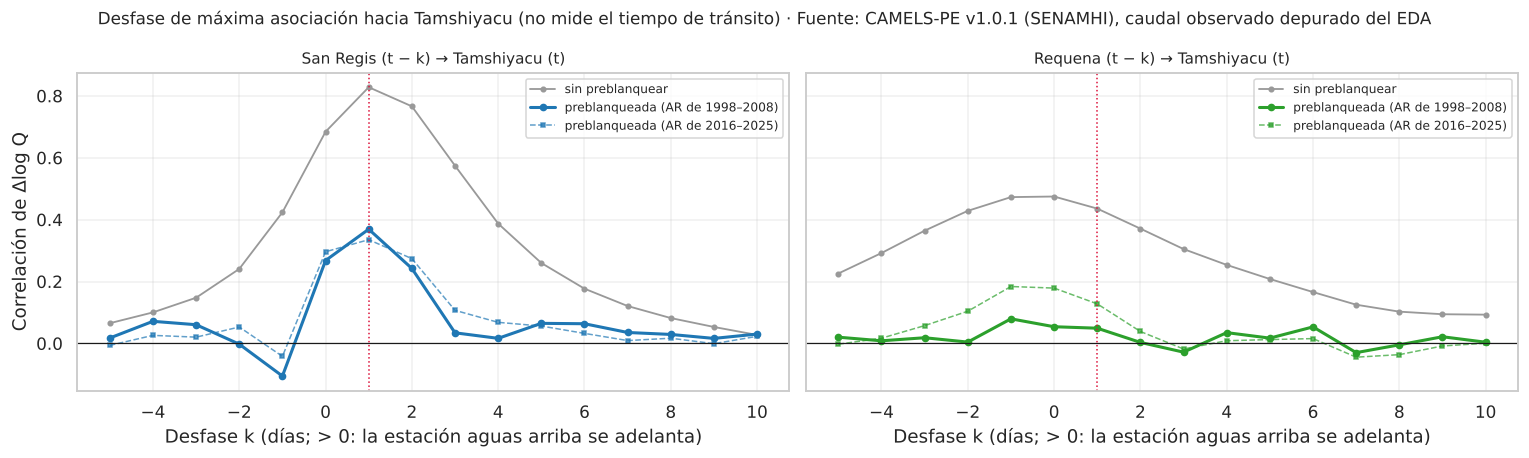

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for a, n in zip(ax, ARR):
    a.plot(list(DESF), CCF[(n, 'sin preblanquear')].values, 'o-', color='0.6', lw=1.2, ms=3, label='sin preblanquear')
    a.plot(list(DESF), CCF[(n, 'AR de 1998–2008')].values, 'o-', color=COLV['+ ' + n], lw=2, ms=4, label='preblanqueada (AR de 1998–2008)')
    a.plot(list(DESF), CCF[(n, 'AR de 2016–2025')].values, 's--', color=COLV['+ ' + n], lw=1, ms=3, alpha=0.7, label='preblanqueada (AR de 2016–2025)')
    a.axhline(0, color='k', lw=0.8); a.axvline(1, color='crimson', ls=':', lw=1)
    a.set_xlabel('Desfase k (días; > 0: la estación aguas arriba se adelanta)'); a.set_title(f'{n} (t − k) → Tamshiyacu (t)', fontsize=10)
    a.grid(True, alpha=0.3); a.legend(fontsize=8)
ax[0].set_ylabel('Correlación de Δlog Q')
fig.suptitle('Desfase de máxima asociación hacia Tamshiyacu (no mide el tiempo de tránsito) · ' + FUENTE, fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig02_transito_tamshiyacu.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:**
- **San Regis (izquierda):** la curva preblanqueada tiene un pico claro en k = 1, igual con los dos periodos de ajuste del AR.
- **Requena (derecha):** la curva preblanqueada queda cerca de cero.
- **La curva gris** (sin preblanquear) de Requena es ancha y casi simétrica alrededor de 0: es coherente con un ciclo común más que con una onda que viaja de una estación a la otra.

### 3.1 Comprobación aproximada de plausibilidad física
**Plausibilidad física:** distancia en línea recta entre estaciones (coordenadas de CAMELS-PE) y la celeridad que implicaría cada desfase. CAMELS-PE no informa la distancia por el cauce; se muestra un rango con una sinuosidad supuesta de 1.3 a 2.0.
**Por qué:** si el desfase estadístico exigiera una celeridad imposible, el problema estaría en los datos o en la alineación temporal. Con distancias en línea recta, una sinuosidad supuesta y celeridades típicas, es una comprobación de **plausibilidad**, no una medición del tránsito.

In [7]:
st = pd.read_csv(C.asegurar_camels() / '01_metadata' / 'stations.csv').set_index('gauge_id')
def km(a, b):
    la1, lo1, la2, lo2 = np.radians([st.loc[a, 'gauge_lat'], st.loc[a, 'gauge_lon'], st.loc[b, 'gauge_lat'], st.loc[b, 'gauge_lon']])
    return float(2 * 6371 * np.arcsin(np.sqrt(np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2)))
GID = {'Tamshiyacu': 'PE_240103', 'Racarumi': 'PE_200907', **{n: A.ARRIBA[n]['gid'] for n in A.ARRIBA}}
filas_f = []
for arriba, abajo in [('San Regis', 'Tamshiyacu'), ('Requena', 'Tamshiyacu'), ('Cirato', 'Racarumi')]:
    d = km(GID[arriba], GID[abajo])
    filas_f.append({'tramo': f'{arriba} → {abajo}', 'distancia en línea recta (km)': d,
                    'cauce supuesto (km, sinuosidad 1.3–2.0)': f'{1.3 * d:,.0f}–{2.0 * d:,.0f}',
                    'celeridad si tarda 1 día (m/s)': f'{1.3 * d * 1000 / 86400:.1f}–{2.0 * d * 1000 / 86400:.1f}',
                    'tiempo con celeridad 1–3 m/s (h)': f'{1.3 * d * 1000 / 3 / 3600:.0f}–{2.0 * d * 1000 / 1 / 3600:.0f}'})
fis = pd.DataFrame(filas_f).set_index('tramo')
fis.to_csv(RUTA_TAB / 'tabla_verificacion_fisica.csv')
fis.round(1)

,distancia en línea recta (km),"cauce supuesto (km, sinuosidad 1.3–2.0)",celeridad si tarda 1 día (m/s),tiempo con celeridad 1–3 m/s (h)
tramo,,,,
San Regis → Tamshiyacu,100.2,130–200,1.5–2.3,12–56
Requena → Tamshiyacu,137.7,179–275,2.1–3.2,17–77
Cirato → Racarumi,27.0,35–54,0.4–0.6,3–15


**Interpretación:**
- **San Regis → Tamshiyacu:** 100 km en línea recta y 130–200 km por un cauce supuesto. Tardar 1 día exige una celeridad de 1.5–2.3 m/s, plausible para la onda de crecida de un río de llanura de este tamaño. El desfase estadístico **es compatible** con la física; no la confirma, porque la distancia por el cauce y la celeridad son supuestas.
- **Requena → Tamshiyacu:** 138 km en línea recta y 180–275 km por el cauce del Ucayali, que es muy meándrico. Con celeridades de 1–3 m/s debería tardar entre 17 y 77 horas, así que se esperaría un desfase de **1 a 3 días**, y la correlación no lo muestra. Hay dos explicaciones posibles, que estos datos no permiten separar:
  - el remanso del Marañón en la confluencia y el almacenamiento de la llanura de inundación amortiguan y mezclan la señal del Ucayali;
  - la referencia de fechas de Requena tiene un problema que el EDA no detectó.
- **Cirato → Racarumi:** 27 km en línea recta (35–54 km por el cauce). Con 1–3 m/s el agua tardaría **3 a 15 horas**, menos de un día (estimación aproximada).

---
## 4. Los seis modelos con el caudal aguas arriba: ajuste y representación
Los seis modelos se ajustan con cada configuración (`integrado.ajustar`: búsqueda de hiperparámetros en 2012–2015 con la malla del protocolo, ajuste final con sus semillas y reentrenamiento con entrenamiento + validación para la prueba); la tabla muestra qué recibe cada familia. Un ajuste guardado se reutiliza solo si su identidad completa (datos, filas, partición, malla, semillas, código y software) es idéntica.

In [8]:
R, registro = I.ajustar(x)
P = I.pronosticos(x, R)
CONJ = x.conjuntos
filas = []
for (conj, lat), dd in x.D.items():
    filas.append({'conjunto': I.etiqueta(conj, lat), 'disponibilidad': I.disponibilidad(conj, lat), 'variables tabulares': dd.X.shape[1],
                  'canales LSTM': 4 + dd.E.shape[2], 'prueba': f"{rango(dd.ip)} ({len(dd.ip):,})", 'prueba extendida': len(dd.mx.fechas),
                  'minutos de ajuste (6 modelos)': sum(R[(conj, lat, n)]['segundos'] for n in MODELOS) / 60})
inv_c = pd.DataFrame(filas).set_index('conjunto')
inv_c.to_csv(RUTA_TAB / 'tabla_conjuntos.csv')
registro.to_csv(RUTA_TAB / 'tabla_registro_ajustes.csv', index=False)
ficha = pd.DataFrame([f for (c, l), dd in x.D.items() if (c, l) in [('Q+' + SR + '+' + RQ, 0), ('Q+' + SR + '+' + RQ, 1)] for f in EN.inventario_entradas(dd)])
ficha.to_csv(RUTA_TAB / 'tabla_representacion_por_familia.csv', index=False)
print(f"Ajustes: {len(registro)} (leídos de una caché con identidad idéntica: {int(registro['leído de la caché'].sum())}); "
      f"minutos de ajuste: {registro['minutos de ajuste'].sum():,.0f}")
display(inv_c.round(1))
ficha.set_index(['conjunto', 'latencia (d)', 'fuente'])

Ajustes: 42 (leídos de una caché con identidad idéntica: 42); minutos de ajuste: 67


,disponibilidad,variables tabulares,canales LSTM,prueba,prueba extendida,minutos de ajuste (6 modelos)
conjunto,,,,,,
Q,solo caudal local (hasta t),32,4,"2016-01-01 a 2025-12-01 (2,806)",2969,5.5
Q+SR,caudal local hasta t; San Regis hasta t (dispo...,62,6,"2016-01-01 a 2025-12-01 (2,806)",2969,14.8
Q+SR (t−1),caudal local hasta t; San Regis hasta t−1,62,6,"2016-01-01 a 2025-12-01 (2,806)",2969,8.2
Q+RQ,caudal local hasta t; Requena hasta t (disponi...,62,6,"2016-01-01 a 2020-03-31 (1,098)",1148,7.4
Q+RQ (t−1),caudal local hasta t; Requena hasta t−1,62,6,"2016-01-01 a 2020-03-31 (1,098)",1148,8.2
Q+SR+RQ,"caudal local hasta t; San Regis, Requena hasta...",92,8,"2016-01-01 a 2020-03-31 (1,098)",1148,11.5
Q+SR+RQ (t−1),"caudal local hasta t; San Regis, Requena hasta...",92,8,"2016-01-01 a 2020-03-31 (1,098)",1148,11.1


tabulares (lineal, RF, XGBoost, MLP)  \
conjunto                latencia (d) fuente                                                           
Q+A:San Regis+A:Requena 0            Q            log Q(t) y 29 cambios diarios (t−29 … t−1) + s...   
                                     A:San Regis                   San Regis: log Q(t) y 29 cambios   
                                     A:Requena                       Requena: log Q(t) y 29 cambios   
                        1            Q            log Q(t) y 29 cambios diarios (t−29 … t−1) + s...   
                                     A:San Regis  San Regis: log Q(t) y 29 cambios (todo desplaz...   
                                     A:Requena    Requena: log Q(t) y 29 cambios (todo desplazad...   

                                                                                                KNN  \
conjunto                latencia (d) fuente                                                           
Q+A:San Regis+A:Requena 0            Q            igual que tabulares; de cada caudal usa el niv...   
                                     A:San Regis  igual que tabulares; de cada caudal usa el niv...   
                                     A:Requena    igual que tabulares; de cada caudal usa el niv...   
                        1            Q            igual que tabulares; de cada caudal usa el niv...   
                                     A:San Regis  igual que tabulares; de cada caudal usa el niv...   
                                     A:Requena    igual que tabulares; de cada caudal usa el niv...   

                                                                                               LSTM  \
conjunto                latencia (d) fuente                                                           
Q+A:San Regis+A:Requena 0            Q            log Q diario t−29 … t (estandarizado) + calend...   
                                     A:San Regis  San Regis: log Q diario y cambio respecto al ú...   
                                     A:Requena    Requena: log Q diario y cambio respecto al últ...   
                        1            Q            log Q diario t−29 … t (estandarizado) + calend...   
                                     A:San Regis  San Regis: log Q diario y cambio respecto al ú...   
                                     A:Requena    Requena: log Q diario y cambio respecto al últ...   

                                                 días cubiertos (tabulares)  \
conjunto                latencia (d) fuente                                   
Q+A:San Regis+A:Requena 0            Q                             t−29 … t   
                                     A:San Regis                   t−29 … t   
                                     A:Requena                     t−29 … t   
                        1            Q                             t−29 … t   
                                     A:San Regis                   t−29 … t   
                                     A:Requena                     t−29 … t   

                                                 días cubiertos (LSTM)  \
conjunto                latencia (d) fuente                              
Q+A:San Regis+A:Requena 0            Q                        t−29 … t   
                                     A:San Regis              t−29 … t   
                                     A:Requena                t−29 … t   
                        1            Q                        t−29 … t   
                                     A:San Regis              t−29 … t   
                                     A:Requena                t−29 … t   

                                                  misma representación temporal  
conjunto                latencia (d) fuente                                      
Q+A:San Regis+A:Requena 0            Q                                     True  
                                     A:San Regis                           True  
                                  

---
## 5. Validación (bloque 2012–2015): ¿qué entrada y qué modelo se elegirían?
(a) NSE medio de los 30 horizontes de cada modelo y configuración en el bloque de selección, y en cada configuración de entradas la regla de selección del estudio entre los seis modelos; (b) el efecto de cada estación con el mismo modelo (ΔNSE medio con IC 90 % y clase; por bandas); (c) la **configuración seleccionada para la magnitud** por escenario de disponibilidad y por periodo de prueba (con San Regis: Q o Q+SR; con Requena: las cuatro), con los candidatos equivalentes al mayor (IC 90 % dentro de ±0.01) y los inconclusos (IC demasiado ancho) por separado. Las configuraciones con Requena se validan en las mismas emisiones que las demás (Requena tiene dato en 2009–2015).

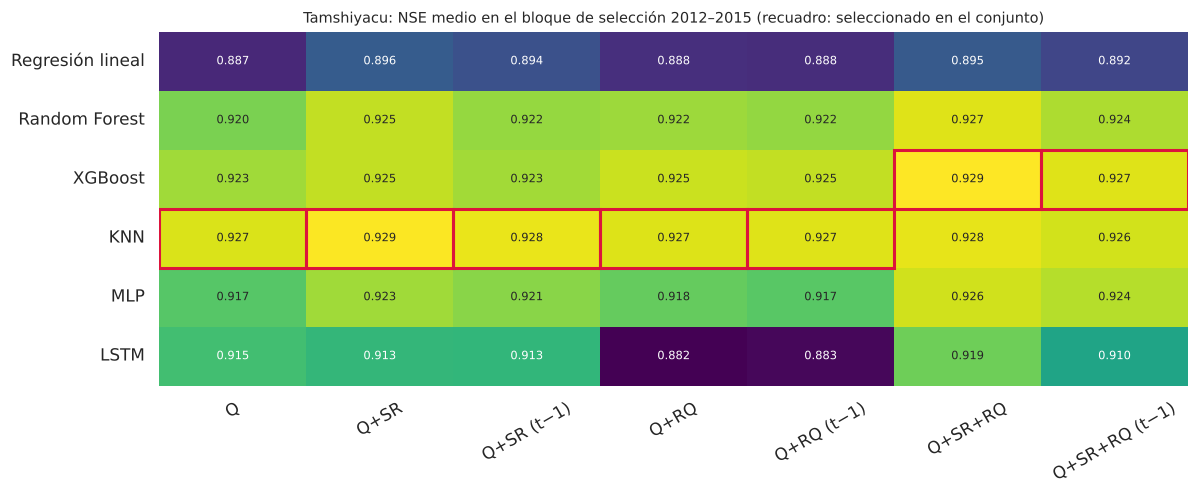

modelo,Regresión lineal,Random Forest,XGBoost,KNN,MLP,LSTM
conjunto,,,,,,
Q,0.8873,0.9197,0.9225,0.9266,0.9168,0.9149
Q+SR,0.8957,0.9250,0.9250,0.9290,0.9226,0.9134
Q+SR (t−1),0.8937,0.9219,0.9227,0.9277,0.9208,0.9131
Q+RQ,0.8885,0.9223,0.9255,0.9268,0.9182,0.8821
Q+RQ (t−1),0.8880,0.9217,0.9250,0.9270,0.9170,0.8830
Q+SR+RQ,0.8952,0.9270,0.9293,0.9276,0.9259,0.9188
Q+SR+RQ (t−1),0.8920,0.9235,0.9270,0.9261,0.9241,0.9096


In [9]:
val = I.tabla_validacion(x, P, R=R)
SELM, metodo_val = I.seleccion_por_conjunto(x, P, modelos=MODELOS, B=B)
val.to_csv(RUTA_TAB / 'tabla_validacion.csv', index=False)
metodo_val.to_csv(RUTA_TAB / 'tabla_seleccion_modelo_por_conjunto.csv', index=False)
fig, a = plt.subplots(figsize=(11, 4.6))
I.fig_validacion(a, x, val, SELM, MODELOS)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig03_validacion.png', dpi=200, bbox_inches='tight'); plt.show()
I.tabla_corta(val, ['conjunto'], 'NSE medio selección', modelos=MODELOS).round(4)

**Figura 3.** NSE medio de los 30 horizontes en el bloque de selección para cada modelo (filas) y configuración (columnas); el recuadro marca el modelo seleccionado en cada configuración con la regla de selección del estudio.

In [10]:
SR_, RQ_, SRRQ_ = 'Q+' + SR, 'Q+' + RQ, 'Q+' + SR + '+' + RQ
COMPARACIONES = [('SR', (SR_, 0), ('Q', 0)), ('SR con latencia 1 d', (SR_, 1), ('Q', 0)), ('retraso de SR (t−1 frente a t)', (SR_, 1), (SR_, 0)),
                 ('RQ', (RQ_, 0), ('Q', 0)), ('RQ con latencia 1 d', (RQ_, 1), ('Q', 0)), ('retraso de RQ (t−1 frente a t)', (RQ_, 1), (RQ_, 0)),
                 ('RQ sobre SR', (SRRQ_, 0), (SR_, 0)), ('SR sobre RQ', (SRRQ_, 0), (RQ_, 0)), ('RQ sobre SR, latencia 1 d', (SRRQ_, 1), (SR_, 1)),
                 ('SR + RQ con latencia 1 d', (SRRQ_, 1), ('Q', 0))]
entrada_val, entrada_val_b = I.efecto_entrada_validacion(x, P, COMPARACIONES, MODELOS, B=B)
entrada_val.to_csv(RUTA_TAB / 'tabla_efecto_entrada_validacion.csv', index=False)
entrada_val_b.to_csv(RUTA_TAB / 'tabla_efecto_entrada_validacion_bandas.csv', index=False)
display(I.tabla_corta(entrada_val, ['entrada'], None, I.fmt_delta, MODELOS))
I.tabla_corta(entrada_val_b, ['entrada', 'banda'], None, I.fmt_g, MODELOS)

modelo,Regresión lineal,Random Forest,XGBoost,KNN,MLP,LSTM
entrada,,,,,,
SR,+0.008 ▲,+0.005 ?,+0.002 =,+0.002 =,+0.006 ▲,-0.002 ?
SR con latencia 1 d,+0.006 ?,+0.002 =,+0.000 =,+0.001 =,+0.004 =,-0.002 ?
retraso de SR (t−1 frente a t),-0.002 =,-0.003 =,-0.002 =,-0.001 =,-0.002 =,-0.000 =
RQ,+0.001 =,+0.003 =,+0.003 =,+0.000 =,+0.001 =,-0.033 ▼
RQ con latencia 1 d,+0.001 =,+0.002 =,+0.002 =,+0.000 =,+0.000 =,-0.032 ▼
retraso de RQ (t−1 frente a t),-0.000 =,-0.001 =,-0.000 =,+0.000 =,-0.001 =,+0.001 =
RQ sobre SR,-0.000 =,+0.002 =,+0.004 ▲,-0.001 =,+0.003 =,+0.005 ?
SR sobre RQ,+0.007 ▲,+0.005 ?,+0.004 =,+0.001 =,+0.008 ▲,+0.037 ▲
"RQ sobre SR, latencia 1 d",-0.002 =,+0.002 =,+0.004 ?,-0.002 =,+0.003 =,-0.004 ?


modelo                                    Regresión lineal Random Forest  \
entrada                        banda                                       
SR                             1–3 días            +37 % +       +26 % +   
                               4–7 días            +17 % +       +16 % +   
                               8–15 días            +9 % +       +10 % +   
                               16–30 días           +7 % +        +5 % ≈   
SR con latencia 1 d            1–3 días             +8 % +        +5 % +   
                               4–7 días             +3 % ≈        +5 % +   
                               8–15 días            +5 % ≈        +6 % +   
                               16–30 días           +6 % ≈        +2 % ≈   
retraso de SR (t−1 frente a t) 1–3 días            -45 % −       -29 % −   
                               4–7 días            -16 % −       -13 % −   
                               8–15 días            -4 % −        -4 % −   
                               16–30 días           -1 % −        -4 % −   
RQ                             1–3 días             -0 % ≈        -1 % ≈   
                               4–7 días             -0 % ≈        +0 % ≈   
                               8–15 días            -0 % ≈        +2 % ≈   
                               16–30 días           +1 % ≈        +4 % ≈   
RQ con latencia 1 d            1–3 días             -1 % ≈        -1 % ≈   
                               4–7 días             -1 % ≈        +0 % ≈   
                               8–15 días            -1 % ≈        +2 % ≈   
                               16–30 días           +1 % ≈        +3 % ≈   
retraso de RQ (t−1 frente a t) 1–3 días             -1 % ≈        +0 % ≈   
                               4–7 días             -1 % ≈        -0 % ≈   
                               8–15 días            -0 % ≈        -0 % ≈   
                               16–30 días           -0 % ≈        -1 % ≈   
RQ sobre SR                    1–3 días             +4 % +        -2 % −   
                               4–7 días             +1 % ≈        -1 % ≈   
                               8–15 días            -2 % ≈        +1 % ≈   
                               16–30 días           -0 % ≈        +3 % ≈   
SR sobre RQ                    1–3 días            +39 % +       +26 % +   
                               4–7 días            +18 % +       +15 % +   
                               8–15 días            +7 % +        +8 % +   
                               16–30 días           +5 % +        +5 % ≈   
RQ sobre SR, latencia 1 d      1–3 días             -1 % ≈        -2 % −   
                               4–7 días             -2 % ≈        -1 % ≈   
                               8–15 días            -3 % ≈        +1 % ≈   
                               16–30 días           -1 % ≈        +3 % ≈   
SR + RQ con latencia 1 d       1–3 días             +8 % +        +3 % +   
                               4–7 días             +1 % ≈        +4 % +   
                               8–15 días            +2 % ≈        +7 % +   
                               16–30 días           +5 % ≈        +4 % ≈   

modelo                                     XGBoost      KNN      MLP     LSTM  
entrada                        banda                                           
SR                             1–3 días    +30 % +  +25 % +  +32 % +  +34 % +  
                               4–7 días    +16 % +  +13 % +  +18 % +  +14 % +  
                               8–15 días    +9 % +   +4 % ≈   +7 % +   +1 % ≈  
                               16–30 días   +1 % ≈   +2 % ≈   +6 % ≈   -4 % ≈  
SR con latencia 1 d            1–3 días     +8 % +   +1 % ≈   +8 % +  +15 % +  
                               4–7 días     +5 % +   -0 % ≈   +6 % +   +4 % ≈  
                               8–15 días    +4 % +   +0 % ≈   +4 % +   -2 % ≈  
                               16–30 días   -1 % ≈   +2 % ≈   +5 % ≈   -3 % ≈  
retraso

In [11]:
PERIODOS = {ALC_SR: lambda c: RQ not in c, ALC_RQ: lambda c: True}
filas, CONFIG, EQUIV, NOPEOR = [], {}, {}, {}
for per, ok in PERIODOS.items():
    for esc in I.ESCENARIOS:
        cand = [k for k in P if ok(k[0]) and I.en_escenario(k[0], k[1], esc)]
        s_ = I.seleccion_configuracion(x, P, cand, B=B)
        CONFIG[(per, esc)], EQUIV[(per, esc)], NOPEOR[(per, esc)] = s_['elegida'], s_['equivalentes'], s_['no_peores']
        filas.append({'periodo de prueba': per, 'escenario': esc, **s_['resumen']})
config = pd.DataFrame(filas).set_index(['periodo de prueba', 'escenario'])
config.to_csv(RUTA_TAB / 'tabla_configuracion_seleccionada.csv')
config.T

periodo de prueba                                            con San Regis (prueba 2016-01 a 2025-12)  \
escenario                                                                                   mismo día   
candidatos                                                                                         12   
mayor NSE medio                                                                            Q+SR · KNN   
NSE medio del mayor                                                                          0.928995   
seleccionada (la más simple entre el mayor y su...                                            Q · KNN   
NSE medio de la seleccionada                                                                 0.926623   
equivalentes al mayor (IC dentro de ±0.01)                                                          2   
inconclusas (IC demasiado ancho; no es equivale...                                                  5   
peores (IC < 0)                                                                                     4   
no demostradas peores (mayor + equivalentes + i...                                                  8   
equivalentes: las 5 de mayor NSE medio              Q+SR · KNN (0.929) | Q · KNN (0.927) | Q+SR · ...   
inconclusas: las 5 de mayor NSE medio               Q+SR · XGBoost (0.925) | Q+SR · MLP (0.923) | ...   

periodo de prueba                                                                                      \
escenario                                                                           un día de retraso   
candidatos                                                                                         12   
mayor NSE medio                                                                      Q+SR (t−1) · KNN   
NSE medio del mayor                                                                          0.927737   
seleccionada (la más simple entre el mayor y su...                                            Q · KNN   
NSE medio de la seleccionada                                                                 0.926623   
equivalentes al mayor (IC dentro de ±0.01)                                                          1   
inconclusas (IC demasiado ancho; no es equivale...                                                  6   
peores (IC < 0)                                                                                     4   
no demostradas peores (mayor + equivalentes + i...                                                  8   
equivalentes: las 5 de mayor NSE medio                     Q+SR (t−1) · KNN (0.928) | Q · KNN (0.927)   
inconclusas: las 5 de mayor NSE medio               Q+SR (t−1) · XGBoost (0.923) | Q · XGBoost (0....   

periodo de prueba                                        común con Requena (prueba 2016-01 a 2020-03)  \
escenario                                                                                   mismo día   
candidatos                                                                                         24   
mayor NSE medio                                                                     Q+SR+RQ · XGBoost   
NSE medio del mayor                                                                          0.929291   
seleccionada (la más simple entre el mayor y su...                                         Q+SR · KNN   
NSE medio de la seleccionada                                                                 0.928995   
equivalentes al mayor (IC dentro de ±0.01)                                                          2   
inconclusas (IC demasiado ancho; no es equivale...                                                  9   
peores (IC < 0)                                                                                    12   
no demostradas peores (mayor + equivalentes + i...                                                 12   
equivalentes: las 5 de mayor NSE medio              Q+SR+RQ · XGBoost (0.929) | Q+SR · KNN (0.929)...   
inconclu

**Interpretación:**
- **Los seis modelos rinden muy parecido en validación.** Con Q, el NSE medio de los 30 horizontes va de 0.887 (regresión lineal) a 0.927 (KNN); con cualquier estación agregada, de 0.882 a 0.929. El KNN es el elegido en cada configuración salvo con San Regis y Requena juntas (XGBoost).
- **Efecto de cada estación con el mismo modelo (ΔNSE medio de 2012–2015):**
  - **San Regis:** +0.002 a +0.008 con cinco modelos y −0.002 con la LSTM (mejora demostrada con la regresión lineal y el MLP; equivalente con XGBoost y KNN; inconclusa con Random Forest y la LSTM). En el NSE medio parece poco, pero **por bandas reduce el error de los seis modelos en 25–37 % a 1–3 días y en 13–18 % a 4–7 días** (IC 90 % > 0). Con un día de retraso conserva 1–15 % a 1–3 días.
  - **Requena:** equivalente con cinco modelos y **peor con la LSTM** (−0.033); por bandas no reduce el error y con KNN y LSTM lo aumenta a 1–7 días. Sobre San Regis no agrega nada demostrable.
- **Selección para la magnitud (regla de selección del estudio).** El NSE medio de 30 horizontes diluye la ganancia de corto plazo: las diferencias entre configuraciones caben casi siempre en el margen de ±0.01.
  - **Periodo con San Regis:** el mayor NSE medio es Q+SR · KNN (0.929; con retraso, Q+SR (t−1) · KNN, 0.928), pero **Q · KNN (0.927) es equivalente y tiene menos fuentes: se elige Q · KNN en los dos escenarios.**
  - **Periodo con Requena:** con las fuentes hasta t, el mayor es Q+SR+RQ · XGBoost (0.929) y se elige **Q+SR · KNN** (0.929, equivalente y con una fuente menos; Q · KNN no resulta equivalente a ese máximo). Con un día de retraso se elige **Q · KNN**.
  - Además del mayor, hay 1–2 candidatos equivalentes y 5–6 inconclusos en el periodo con San Regis, y 2–5 equivalentes y 9–10 inconclusos en el periodo común con Requena: la elección es poco nítida (los inconclusos no son equivalencias, sino comparaciones sin evidencia suficiente). La ganancia por bandas de San Regis, que sí es nítida, no es lo que mide la regla fijada antes de ejecutar; se informa sin cambiar la regla.

---
## 6. Prueba: magnitud del caudal y horizonte útil
(a) Métricas y horizonte útil de cada configuración **en cada periodo**: con San Regis (prueba 2016-01 a 2025-12) Q y Q+SR; común con Requena (prueba 2016-01 a 2020-03) las cuatro, todas en las mismas emisiones; (b) ganancia G de cada estación con el mismo modelo por bandas (IC 90 %), en las emisiones comunes de cada comparación, y si la validación la anticipaba; (c) cada modelo frente al seleccionado en validación para su configuración; (d) las configuraciones seleccionadas en validación, evaluadas sin cambiarlas.

In [12]:
claves_sr = [k for k in P if RQ not in k[0]]
t1, HZ_SR, TAB_SR = I.metricas_prueba(x, P, claves_sr, ip=IP_SR, B=B)
t2, HZ_RQ, TAB_RQ = I.metricas_prueba(x, P, list(P), ip=IP_RQ, B=B)
prueba = pd.concat([t1.assign(**{'periodo de prueba': ALC_SR}), I.referencias_prueba(x, IP_SR).assign(**{'periodo de prueba': ALC_SR}),
                    t2.assign(**{'periodo de prueba': ALC_RQ}), I.referencias_prueba(x, IP_RQ).assign(**{'periodo de prueba': ALC_RQ})],
                   ignore_index=True)
prueba.to_csv(RUTA_TAB / 'tabla_metricas_prueba.csv', index=False)
pm = prueba[prueba['modelo'].isin(MODELOS)]
display(I.tabla_corta(pm, ['periodo de prueba', 'conjunto'], 'NSE medio', modelos=MODELOS).round(3))
I.tabla_corta(pm, ['periodo de prueba', 'conjunto'], 'H cota 95 % (d)', modelos=MODELOS)

modelo                                                      Regresión lineal  \
periodo de prueba                            conjunto                          
con San Regis (prueba 2016-01 a 2025-12)     Q                         0.877   
                                             Q+SR                      0.890   
                                             Q+SR (t−1)                0.887   
común con Requena (prueba 2016-01 a 2020-03) Q                         0.826   
                                             Q+SR                      0.837   
                                             Q+SR (t−1)                0.832   
                                             Q+RQ                      0.823   
                                             Q+RQ (t−1)                0.821   
                                             Q+SR+RQ                   0.833   
                                             Q+SR+RQ (t−1)             0.826   

modelo                                                      Random Forest  \
periodo de prueba                            conjunto                       
con San Regis (prueba 2016-01 a 2025-12)     Q                      0.904   
                                             Q+SR                   0.908   
                                             Q+SR (t−1)             0.906   
común con Requena (prueba 2016-01 a 2020-03) Q                      0.849   
                                             Q+SR                   0.853   
                                             Q+SR (t−1)             0.850   
                                             Q+RQ                   0.845   
                                             Q+RQ (t−1)             0.844   
                                             Q+SR+RQ                0.849   
                                             Q+SR+RQ (t−1)          0.843   

modelo                                                      XGBoost    KNN  \
periodo de prueba                            conjunto                        
con San Regis (prueba 2016-01 a 2025-12)     Q                0.908  0.906   
                                             Q+SR             0.911  0.910   
                                             Q+SR (t−1)       0.909  0.907   
común con Requena (prueba 2016-01 a 2020-03) Q                0.852  0.850   
                                             Q+SR             0.856  0.855   
                                             Q+SR (t−1)       0.851  0.849   
                                             Q+RQ             0.845  0.850   
                                             Q+RQ (t−1)       0.845  0.850   
                                             Q+SR+RQ          0.849  0.857   
                                             Q+SR+RQ (t−1)    0.842  0.852   

modelo                                                        MLP   LSTM  
periodo de prueba                            conjunto                     
con San Regis (prueba 2016-01 a 2025-12)     Q              0.907  0.898  
                                             Q+SR           0.913  0.905  
                                             Q+SR (t−1)     0.911  0.905  
común con Requena (prueba 2016-01 a 2020-03) Q              0.870  0.854  
                                             Q+SR           0.874  0.851  
                                             Q+SR (t−1)     0.869  0.849  
                                             Q+RQ           0.862  0.844  
                                             Q+RQ (t−1)     0.863  0.829  
                                             Q+SR+RQ        0.865  0.852  
                                             Q+SR+RQ (t−1)  0.859  0.848

modelo                                                      Regresión lineal  \
periodo de prueba                            conjunto                          
con San Regis (prueba 2016-01 a 2025-12)     Q                          21.0   
                                             Q+SR                       24.0   
                                             Q+SR (t−1)                 24.0   
común con Requena (prueba 2016-01 a 2020-03) Q                          15.0   
                                             Q+SR                       16.0   
                                             Q+SR (t−1)                 15.0   
                                             Q+RQ                       15.0   
                                             Q+RQ (t−1)                 14.0   
                                             Q+SR+RQ                    16.0   
                                             Q+SR+RQ (t−1)              15.0   

modelo                                                      Random Forest  \
periodo de prueba                            conjunto                       
con San Regis (prueba 2016-01 a 2025-12)     Q                       30.0   
                                             Q+SR                    30.0   
                                             Q+SR (t−1)              30.0   
común con Requena (prueba 2016-01 a 2020-03) Q                       17.0   
                                             Q+SR                    18.0   
                                             Q+SR (t−1)              18.0   
                                             Q+RQ                    16.0   
                                             Q+RQ (t−1)              16.0   
                                             Q+SR+RQ                 17.0   
                                             Q+SR+RQ (t−1)           17.0   

modelo                                                      XGBoost   KNN  \
periodo de prueba                            conjunto                       
con San Regis (prueba 2016-01 a 2025-12)     Q                 30.0  30.0   
                                             Q+SR              30.0  30.0   
                                             Q+SR (t−1)        30.0  30.0   
común con Requena (prueba 2016-01 a 2020-03) Q                 19.0  17.0   
                                             Q+SR              19.0  18.0   
                                             Q+SR (t−1)        18.0  17.0   
                                             Q+RQ              17.0  17.0   
                                             Q+RQ (t−1)        17.0  17.0   
                                             Q+SR+RQ           18.0  18.0   
                                             Q+SR+RQ (t−1)     16.0  18.0   

modelo                                                       MLP  LSTM  
periodo de prueba                            conjunto                   
con San Regis (prueba 2016-01 a 2025-12)     Q              30.0  30.0  
                                             Q+SR           30.0  30.0  
                                             Q+SR (t−1)     30.0  30.0  
común con Requena (prueba 2016-01 a 2020-03) Q              23.0  19.0  
                                             Q+SR           23.0  18.0  
                                             Q+SR (t−1)     23.0  18.0  
                                             Q+RQ           20.0  17.0  
                                             Q+RQ (t−1)     20.0  15.0  
                                             Q+SR+RQ        20.0  18.0  
                                             Q+SR+RQ (t−1)  20.0  18.0

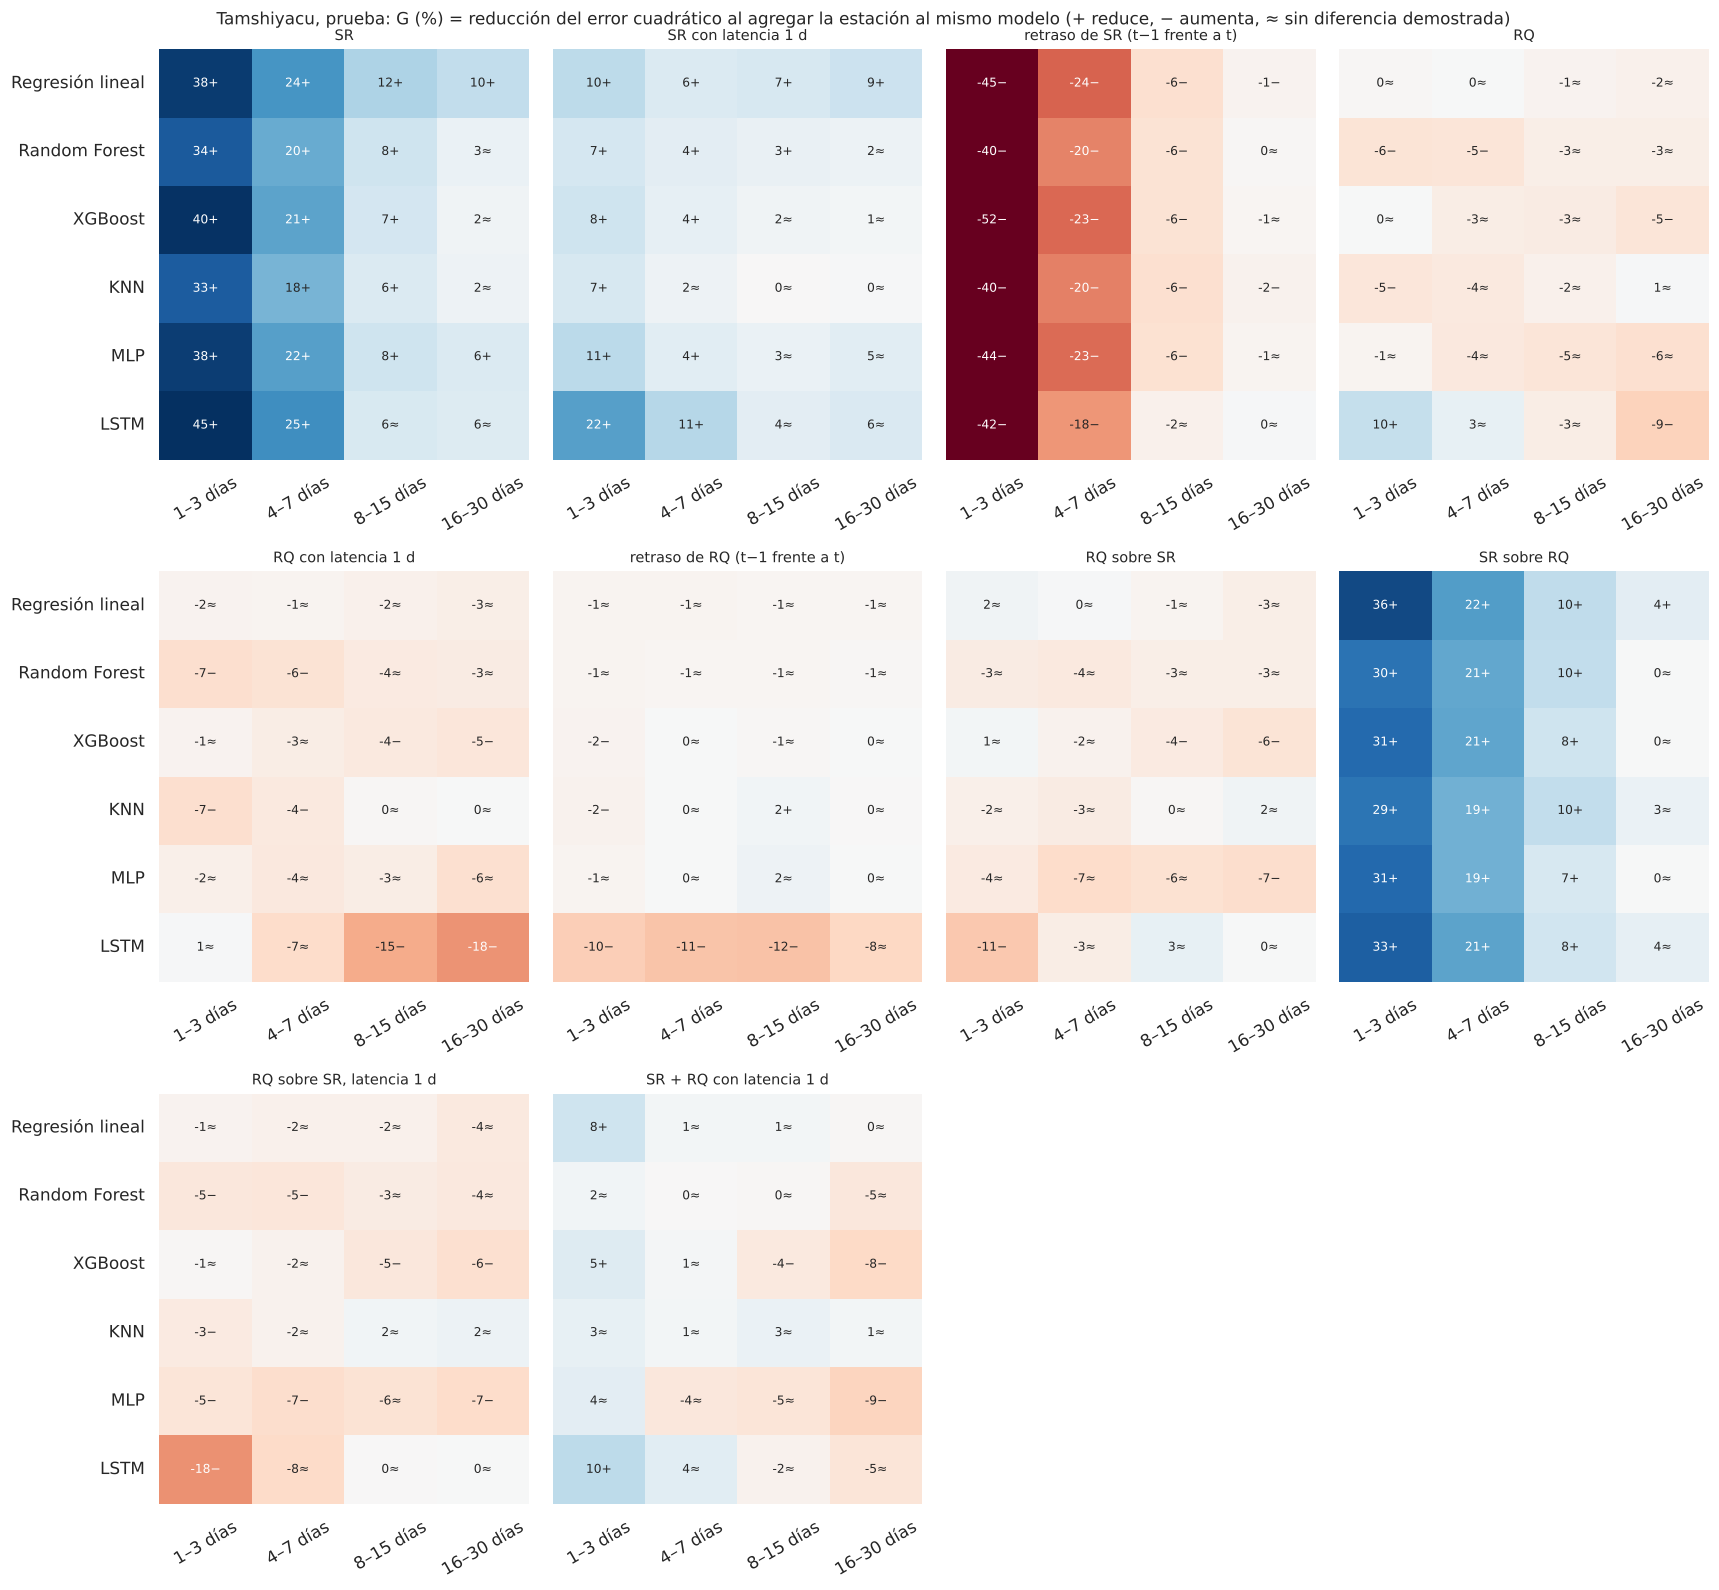

,emisiones,periodo
entrada,,
RQ,1093,2016-01 a 2020-03
RQ con latencia 1 d,1093,2016-01 a 2020-03
RQ sobre SR,1093,2016-01 a 2020-03
"RQ sobre SR, latencia 1 d",1093,2016-01 a 2020-03
SR,2806,2016-01 a 2025-12
SR + RQ con latencia 1 d,1093,2016-01 a 2020-03
SR con latencia 1 d,2806,2016-01 a 2025-12
SR sobre RQ,1093,2016-01 a 2020-03
retraso de RQ (t−1 frente a t),1093,2016-01 a 2020-03


par                                        +/+  ≈/≈  ≈/+  +/≈  −/−  −/≈  ≈/−  \
estación   entrada                                                             
Tamshiyacu SR                               17    5    2    0    0    0    0   
           SR con latencia 1 d               9    8    5    2    0    0    0   
           retraso de SR (t−1 frente a t)    0    3    0    0   18    2    1   
           RQ                                0   14    0    1    2    3    3   
           RQ con latencia 1 d               0   15    0    0    4    1    4   
           retraso de RQ (t−1 frente a t)    0   15    1    0    0    3    5   
           RQ sobre SR                       0   16    0    3    1    1    1   
           SR sobre RQ                      19    3    0    2    0    0    0   
           RQ sobre SR, latencia 1 d         0   15    0    0    3    0    5   
           SR + RQ con latencia 1 d          3   11    0    7    0    0    2   

par                                        −/+  +/−  
estación   entrada                                   
Tamshiyacu SR                                0    0  
           SR con latencia 1 d               0    0  
           retraso de SR (t−1 frente a t)    0    0  
           RQ                                1    0  
           RQ con latencia 1 d               0    0  
           retraso de RQ (t−1 frente a t)    0    0  
           RQ sobre SR                       0    2  
           SR sobre RQ                       0    0  
           RQ sobre SR, latencia 1 d         0    1  
           SR + RQ con latencia 1 d          0    1

modelo                                    Regresión lineal Random Forest  \
entrada                        banda                                       
SR                             1–3 días            +38 % +       +34 % +   
                               4–7 días            +24 % +       +20 % +   
                               8–15 días           +12 % +        +8 % +   
                               16–30 días          +10 % +        +3 % ≈   
SR con latencia 1 d            1–3 días            +10 % +        +7 % +   
                               4–7 días             +6 % +        +4 % +   
                               8–15 días            +7 % +        +3 % +   
                               16–30 días           +9 % +        +2 % ≈   
retraso de SR (t−1 frente a t) 1–3 días            -45 % −       -40 % −   
                               4–7 días            -24 % −       -20 % −   
                               8–15 días            -6 % −        -6 % −   
                               16–30 días           -1 % −        -0 % ≈   
RQ                             1–3 días             -0 % ≈        -6 % −   
                               4–7 días             +0 % ≈        -5 % −   
                               8–15 días            -1 % ≈        -3 % ≈   
                               16–30 días           -2 % ≈        -3 % ≈   
RQ con latencia 1 d            1–3 días             -2 % ≈        -7 % −   
                               4–7 días             -1 % ≈        -6 % −   
                               8–15 días            -2 % ≈        -4 % ≈   
                               16–30 días           -3 % ≈        -3 % ≈   
retraso de RQ (t−1 frente a t) 1–3 días             -1 % ≈        -1 % ≈   
                               4–7 días             -1 % ≈        -1 % ≈   
                               8–15 días            -1 % ≈        -1 % ≈   
                               16–30 días           -1 % ≈        -1 % ≈   
RQ sobre SR                    1–3 días             +2 % ≈        -3 % ≈   
                               4–7 días             +0 % ≈        -4 % ≈   
                               8–15 días            -1 % ≈        -3 % ≈   
                               16–30 días           -3 % ≈        -3 % ≈   
SR sobre RQ                    1–3 días            +36 % +       +30 % +   
                               4–7 días            +22 % +       +21 % +   
                               8–15 días           +10 % +       +10 % +   
                               16–30 días           +4 % +        +0 % ≈   
RQ sobre SR, latencia 1 d      1–3 días             -1 % ≈        -5 % −   
                               4–7 días             -2 % ≈        -5 % −   
                               8–15 días            -2 % ≈        -3 % ≈   
                               16–30 días           -4 % ≈        -4 % ≈   
SR + RQ con latencia 1 d       1–3 días             +8 % +        +2 % ≈   
                               4–7 días             +1 % ≈        -0 % ≈   
                               8–15 días            +1 % ≈        -0 % ≈   
                               16–30 días           -0 % ≈        -5 % ≈   

modelo                                     XGBoost      KNN      MLP     LSTM  
entrada                        banda                                           
SR                             1–3 días    +40 % +  +33 % +  +38 % +  +45 % +  
                               4–7 días    +21 % +  +18 % +  +22 % +  +25 % +  
                               8–15 días    +7 % +   +6 % +   +8 % +   +6 % ≈  
                               16–30 días   +2 % ≈   +2 % ≈   +6 % +   +6 % ≈  
SR con latencia 1 d            1–3 días     +8 % +   +7 % +  +11 % +  +22 % +  
                               4–7 días     +4 % +   +2 % ≈   +4 % +  +11 % +  
                               8–15 días    +2 % ≈   -0 % ≈   +3 % ≈   +4 % ≈  
                               16–30 días   +1 % ≈   +0 % ≈   +5 % ≈   +6 % ≈  
retraso

In [13]:
entrada_pru = pd.concat([I.efecto_entrada_prueba(x, P, [c for c in COMPARACIONES if RQ not in c[1][0] + c[2][0]], MODELOS, B=B),
                         I.efecto_entrada_prueba(x, P, [c for c in COMPARACIONES if RQ in c[1][0] + c[2][0]], MODELOS, B=B, ip=IP_RQ)], ignore_index=True)
entrada_pru.to_csv(RUTA_TAB / 'tabla_efecto_entrada_prueba.csv', index=False)
conc = I.concordancia(entrada_val_b, entrada_pru)
conc.to_csv(RUTA_TAB / 'tabla_concordancia_validacion_prueba.csv')
I.fig_ganancias(entrada_pru, 'Tamshiyacu', [c[0] for c in COMPARACIONES], RUTA_FIG / 'fig04_efecto_entrada.png',
                'Tamshiyacu, prueba: G (%) = reducción del error cuadrático al agregar la estación al mismo modelo (+ reduce, − aumenta, ≈ sin diferencia demostrada)', MODELOS)
plt.show()
display(entrada_pru.groupby('entrada')[['emisiones', 'periodo']].first())
display(conc)
I.tabla_corta(entrada_pru, ['entrada', 'banda'], None, I.fmt_g, MODELOS)

**Figura 4.** Prueba: G (%) de cada estación con el mismo modelo por banda de horizonte. Las comparaciones con Requena se calculan en el periodo común con Requena; las de San Regis solo, en todo el periodo con San Regis.

**Interpretación (prueba, mismo modelo y mismas emisiones):**
- **San Regis reduce el error de los seis modelos** (2016-01 a 2025-12, 2 806 emisiones): **33–45 % a 1–3 días, 18–25 % a 4–7 días** y 6–12 % a 8–15 días (IC 90 % > 0 en cinco de seis; la LSTM, sin diferencia demostrada); a 16–30 días, +2–10 %, demostrado solo con la regresión lineal y el MLP.
- **Con un día de retraso conserva una parte:** 7–22 % a 1–3 días con los seis modelos y 2–11 % a 4–7 días (demostrado con cinco). Frente a tenerlo el mismo día, **con el dato hasta t−1 el error cuadrático a 1–3 días es 40–52 % mayor**: el dato del día t es el que más pesa, coherente con el desfase de 1 día (sección 3).
- **Requena** (2016-01 a 2020-03, 1 093 emisiones) **no reduce el error de forma demostrable**: en 18 de 24 pares modelo × banda no hay diferencia demostrada; con Random Forest y KNN lo aumenta 5–6 % a 1–3 días, con XGBoost y la LSTM a 16–30 días, y solo con la LSTM lo reduce (10 % a 1–3 días). Con un día de retraso, lo mismo o peor. **Sobre San Regis no agrega nada** (20 de 24 pares sin diferencia demostrada y 4 con aumento del error), mientras que **San Regis sobre Requena reduce el error 29–36 % a 1–3 días** con los seis modelos.
- **La validación anticipó la prueba:** para San Regis, 17 de 24 pares modelo × banda reducen el error en las dos y ninguno cambia de signo; para Requena, la mayoría queda sin diferencia en las dos.

In [14]:
metodo_pru = I.efecto_metodo(x, P, SELM, B=B)
metodo_pru.to_csv(RUTA_TAB / 'tabla_efecto_metodo_prueba.csv', index=False)
display(I.tabla_corta(metodo_pru, ['conjunto', 'referencia'], None, I.fmt_delta, MODELOS))
# Configuraciones seleccionadas en validación, evaluadas en la prueba de su periodo (sin cambiar la selección)
filas = []
for (per, esc), k in CONFIG.items():
    tab = t1 if 'San Regis' in per else t2
    r_ = tab[(tab['conjunto'] == I.etiqueta(k[0], k[1])) & (tab['modelo'] == k[2])].iloc[0]
    etq_esc = {I.etiqueta(c, l) for (c, l, n) in P if PERIODOS[per](c) and I.en_escenario(c, l, esc)}
    tab_e = tab[tab['conjunto'].isin(etq_esc) & tab['modelo'].isin(MODELOS)]
    mejor = tab_e.loc[tab_e['NSE medio'].idxmax()]
    filas.append({'periodo de prueba': per, 'escenario': esc, 'seleccionada en validación': I.nombre(k), 'NSE medio (prueba)': r_['NSE medio'],
                  'H cota 95 % (d)': r_['H cota 95 % (d)'], 'mayor NSE medio observado en la prueba (no se elige con él)': f"{mejor['conjunto']} · {mejor['modelo']} ({mejor['NSE medio']:.3f})"})
sel_prueba = pd.DataFrame(filas).set_index(['periodo de prueba', 'escenario'])
sel_prueba.to_csv(RUTA_TAB / 'tabla_seleccionadas_en_prueba.csv')
sel_prueba.round(3)

,modelo,Regresión lineal,Random Forest,XGBoost,KNN,MLP,LSTM
conjunto,referencia,,,,,,
Q,Q · KNN,-0.030 ▼,-0.002 =,+0.001 =,NaN,+0.000 ?,-0.008 ?
Q+SR,Q+SR · KNN,-0.020 ▼,-0.001 =,+0.002 =,NaN,+0.003 ?,-0.004 ?
Q+SR (t−1),Q+SR (t−1) · KNN,-0.020 ▼,-0.000 =,+0.002 =,NaN,+0.004 ?,-0.002 ?
Q+RQ,Q+RQ · KNN,-0.027 ?,-0.005 ?,-0.004 ?,NaN,+0.012 ?,-0.006 ?
Q+RQ (t−1),Q+RQ (t−1) · KNN,-0.028 ?,-0.006 ?,-0.004 ?,NaN,+0.013 ?,-0.020 ?
Q+SR+RQ,Q+SR+RQ · XGBoost,-0.016 ?,+0.000 ?,NaN,+0.007 ?,+0.016 ▲,+0.003 ?
Q+SR+RQ (t−1),Q+SR+RQ (t−1) · XGBoost,-0.016 ?,+0.001 ?,NaN,+0.010 ?,+0.017 ▲,+0.006 ?


seleccionada en validación  \
periodo de prueba                            escenario                                      
con San Regis (prueba 2016-01 a 2025-12)     mismo día                            Q · KNN   
                                             un día de retraso                    Q · KNN   
común con Requena (prueba 2016-01 a 2020-03) mismo día                         Q+SR · KNN   
                                             un día de retraso                    Q · KNN   

                                                                NSE medio (prueba)  \
periodo de prueba                            escenario                               
con San Regis (prueba 2016-01 a 2025-12)     mismo día                       0.906   
                                             un día de retraso               0.906   
común con Requena (prueba 2016-01 a 2020-03) mismo día                       0.855   
                                             un día de retraso               0.850   

                                                                H cota 95 % (d)  \
periodo de prueba                            escenario                            
con San Regis (prueba 2016-01 a 2025-12)     mismo día                       30   
                                             un día de retraso               30   
común con Requena (prueba 2016-01 a 2020-03) mismo día                       18   
                                             un día de retraso               17   

                                                               mayor NSE medio observado en la prueba (no se elige con él)  
periodo de prueba                            escenario                                                                      
con San Regis (prueba 2016-01 a 2025-12)     mismo día                                         Q+SR · MLP (0.913)           
                                             un día de retraso                           Q+SR (t−1) · MLP (0.911)           
común con Requena (prueba 2016-01 a 2020-03) mismo día                                         Q+SR · MLP (0.874)           
                                             un día de retraso                                    Q · MLP (0.870)

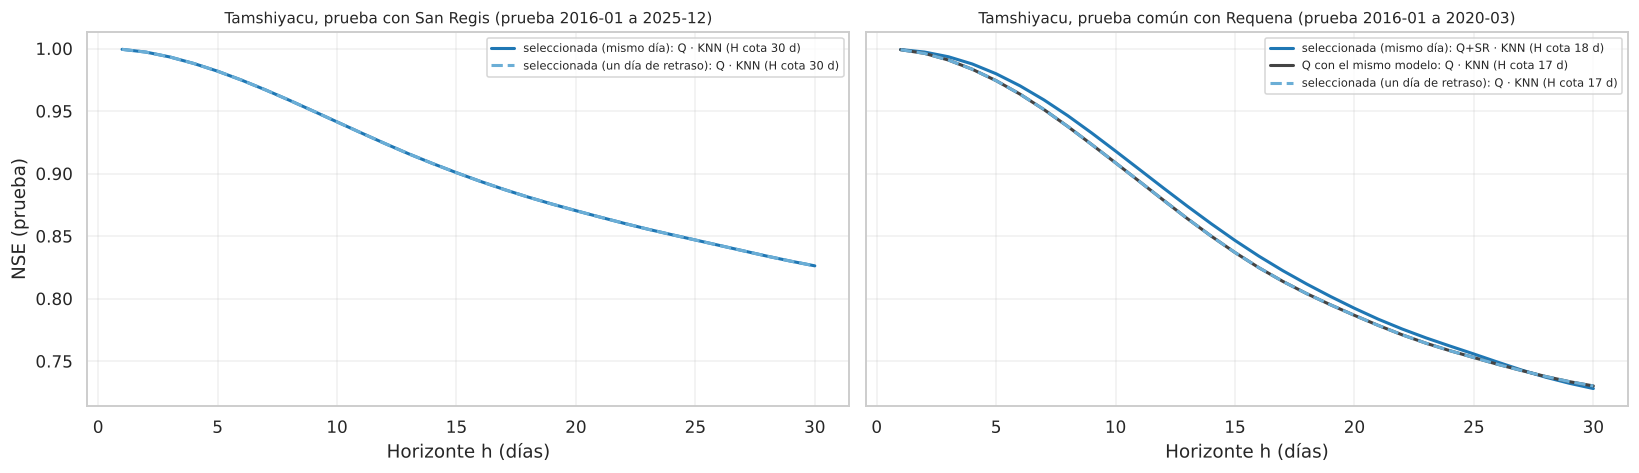

In [15]:
hh = np.array(C.HORIZONTES)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
for a, (per, TB, HZ_) in zip(ax, [(ALC_SR, TAB_SR, HZ_SR), (ALC_RQ, TAB_RQ, HZ_RQ)]):
    vistas = set()
    for esc, ls in [('mismo día', '-'), ('un día de retraso', '--')]:
        k = CONFIG[(per, esc)]
        for kk, col, et in [(k, '#1f77b4' if esc == 'mismo día' else '#6baed6', f'seleccionada ({esc})'), (('Q', 0, k[2]), '#444444', 'Q con el mismo modelo')]:
            if (kk, ls) in vistas:
                continue
            vistas.add((kk, ls))
            a.plot(hh, TB[kk]['NSE'], color=col, ls=ls, lw=2, label=f"{et}: {I.nombre(kk)} (H cota {HZ_[kk]['H_cota']} d)")
    a.grid(True, alpha=0.3); a.set_xlabel('Horizonte h (días)'); a.set_title(f'Tamshiyacu, prueba {per}', fontsize=10); a.legend(fontsize=7.5)
ax[0].set_ylabel('NSE (prueba)')
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig05_seleccionadas_nse_horizonte.png', dpi=200, bbox_inches='tight'); plt.show()

**Figura 5.** NSE por horizonte en la prueba de la configuración seleccionada en validación (continua: mismo día; discontinua: un día de retraso) frente al mismo modelo con solo caudal, en cada periodo; en la leyenda, la cota 95 % del horizonte útil.

**Interpretación:**
- **Efecto del método con la misma fuente:** los no lineales quedan a ±0.01 del elegido en validación o inconclusos; la regresión lineal queda por debajo (−0.016 a −0.030; peor demostrado con Q y Q+SR). La única diferencia demostrada a favor de otro modelo es el **MLP en el periodo con Requena** (+0.016 a +0.017 frente a XGBoost con Q+SR+RQ).
- **Las configuraciones elegidas en validación, en la prueba:**
  - **Periodo con San Regis, Q · KNN** (los dos escenarios): NSE medio 0.906 y horizonte útil ≥ 30 días (cota 95 %). El mayor NSE medio de la prueba es Q+SR · MLP (0.913; con retraso, Q+SR (t−1) · MLP, 0.911): la selección deja fuera una ganancia de corto plazo que la validación había mostrado por bandas.
  - **Periodo con Requena:** Q+SR · KNN (mismo día) da 0.855 y H = 18 días; Q · KNN (retraso), 0.850 y 17 días. El mayor de la prueba es el MLP (0.874 con Q+SR; 0.870 con Q). Ese periodo es más difícil (persistencia 0.699 y climatología 0.741, frente a 0.793 y 0.767 en 2016-01 a 2025-12).
- **Horizonte útil:** en 2016-01 a 2025-12, ≥ 30 días con todos los no lineales y 21–24 con la regresión lineal; en el periodo con Requena, 14–23 días. Agregar San Regis lo cambia en 0–3 días: **su aporte está en la magnitud de corto plazo, no en el horizonte útil**.

---
## 7. Caudales elevados
Error en los días con Q(t + h) sobre el P95 de entrenamiento y en los ordinarios, y POD y CSI diarios de superar el P95, a 1, 3 y 7 días, en la prueba con San Regis (Q y Q+SR) y en la común con Requena (las cuatro). Descriptivo: los días altos de la prueba vienen de 3 crecidas y el periodo con Requena casi no tiene días altos.

In [16]:
crec = pd.concat([I.crecidas(x, P, claves_sr, ip=IP_SR).assign(**{'periodo de prueba': ALC_SR}),
                  I.crecidas(x, P, list(P), ip=IP_RQ).assign(**{'periodo de prueba': ALC_RQ})], ignore_index=True)
crec.to_csv(RUTA_TAB / 'tabla_crecidas.csv', index=False)
display(crec.groupby('periodo de prueba')['días altos'].max().rename('días sobre el P95 (máx. por horizonte)').to_frame())
crec[crec['periodo de prueba'].str.startswith('con San Regis')].pivot_table(index=['h', 'conjunto'], columns='modelo', values='MAE altos (m³/s)', sort=False)[MODELOS].round(0)

,días sobre el P95 (máx. por horizonte)
periodo de prueba,
común con Requena (prueba 2016-01 a 2020-03),0
con San Regis (prueba 2016-01 a 2025-12),73


modelo        Regresión lineal  Random Forest  XGBoost    KNN    MLP    LSTM
h conjunto                                                                  
1 Q                      133.0          105.0    111.0  100.0  110.0   223.0
  Q+SR                   109.0          116.0    111.0  101.0  104.0   115.0
  Q+SR (t−1)             126.0          107.0    110.0  102.0  109.0   162.0
3 Q                      537.0          236.0    313.0  245.0  319.0   564.0
  Q+SR                   411.0          285.0    329.0  232.0  339.0   264.0
  Q+SR (t−1)             530.0          250.0    303.0  228.0  363.0   444.0
7 Q                     1496.0          357.0    617.0  432.0  534.0  1029.0
  Q+SR                  1465.0          528.0    609.0  367.0  654.0   528.0
  Q+SR (t−1)            1668.0          495.0    554.0  377.0  803.0   884.0

**Interpretación (descriptiva):**
- **Periodo con San Regis:** 73 días sobre el P95 (47 603 m³/s) como máximo por horizonte, de solo 3 crecidas (2019, solo la subida; 2022; 2025). El periodo con Requena **no tiene ningún día alto**.
- **En los días ordinarios San Regis reduce el error de todos los modelos** (por ejemplo, a 3 días el MAE baja de 657–874 a 511–663 m³/s). **En los días altos no hay un patrón:** baja con la regresión lineal, el KNN y la LSTM y sube con Random Forest, XGBoost y el MLP (a 3 días, de 236–564 a 232–411 m³/s). Con 3 eventos no se puede separar el efecto de la estación del de cada crecida.
- El POD diario de superar el P95 es alto con todos los modelos a 1–3 días (≥ 0.80) y no cambia de forma consistente con San Regis.

---
## 8. Anticipación de nuevos cruces del P95: ¿hay eventos para evaluarla?
Conteo, con la definición del cuaderno 04 (elegibilidad causal, universo de cruces verificables), los nuevos cruces del P95 de Tamshiyacu evaluables en el bloque de calibración de la regla (2009–2011), en el de comparación de candidatos (2012–2015) y en cada periodo de prueba. El protocolo de avisos solo se aplica si hay eventos para calibrar, comparar y evaluar.

In [17]:
cruces = pd.DataFrame([{**I.conteo_cruces(x, IP_SR), 'periodo de prueba': ALC_SR},
                       {**I.conteo_cruces(x, IP_RQ), 'periodo de prueba': ALC_RQ}]).set_index('periodo de prueba')
cruces.to_csv(RUTA_TAB / 'tabla_cruces_evaluables.csv')
cruces

,estación,P95 (m³/s),cruces evaluables 2009–2011 (regla),cruces evaluables 2012–2015 (comparación),cruces evaluables en la prueba
periodo de prueba,,,,,
con San Regis (prueba 2016-01 a 2025-12),Tamshiyacu,47602.819185,2,2,3
común con Requena (prueba 2016-01 a 2020-03),Tamshiyacu,47602.819185,2,2,0


**Interpretación:** **en Tamshiyacu no hay eventos para evaluar un sistema de avisos.** Con estas filas hay 2 nuevos cruces evaluables para calibrar la regla (2009–2011), 2 para comparar candidatos (2012–2015), **3 en la prueba con San Regis y ninguno en la prueba común con Requena**. Con esos conteos un sistema que avise 2 de 3 no se distingue de uno que avise 1 de 3, así que **no se selecciona ni se evalúa un sistema de avisos con las estaciones aguas arriba**. Una mejora de la magnitud de corto plazo (sección 6) no basta para afirmar que aumente o disminuya la anticipación de crecidas.

---
## 9. Muestra extendida por horizonte
Para cada configuración y horizonte, la muestra común (emisiones con los 30 caudales futuros) frente a la extendida (todas las emisiones con entrada válida; cada horizonte con los objetivos que existan): emisiones, NSE y habilidad frente a persistencia y climatología.

In [18]:
ext = I.muestra_extendida(x, P)
ext.drop(columns='banda').to_csv(RUTA_TAB / 'tabla_muestra_extendida.csv', index=False)
I.resumen_extendida(ext).round(3)

combinaciones  emisiones_extendida_medias  \
estación   banda                                                   
Tamshiyacu 1–3 días              126                    1923.000   
           4–7 días              168                    1921.393   
           8–15 días             336                    1919.125   
           16–30 días            630                    1913.590   

                       ΔNSE_mediana  ΔNSE_min  ΔNSE_max  \
estación   banda                                          
Tamshiyacu 1–3 días           0.000     0.000     0.001   
           4–7 días           0.002     0.000     0.005   
           8–15 días          0.006     0.002     0.012   
           16–30 días         0.009     0.004     0.015   

                       habilidad_cambia_de_signo  
estación   banda                                  
Tamshiyacu 1–3 días                            0  
           4–7 días                            0  
           8–15 días                           0  
           16–30 días                         10

**Interpretación:** la muestra extendida agrega 120–155 emisiones por horizonte en 2016-01 a 2025-12 y ~50 en el periodo con Requena. **No cambia las conclusiones:** el NSE cambia entre 0.000 y +0.015 (mediana +0.009 a 16–30 días) y la habilidad frente a persistencia o climatología cambia de signo en 10 de 630 combinaciones, todas a 16–30 días, donde la habilidad ya era cercana a cero.

---
## 10. Racarumi y Cirato (exploratorio)
En el único periodo con fechas confiables en ambas estaciones (2022-08-01 a 2023-08-31):
1. correlación cruzada preblanqueada de Δlog Q (AR ajustado a Cirato en ese mismo periodo, el único disponible);
2. **Q frente a Q + Cirato** con los **seis modelos**, un modelo por horizonte (1, 2 y 3 días), ventanas de 7 días e **hiperparámetros fijos** elegidos antes de ejecutar (`entradas.CIRATO_FIJOS`): con 13 meses no hay entrenamiento ni validación del protocolo con Cirato, así que **no se hace una selección** como en Tamshiyacu. Dos modos que no se combinan:
   - **retrospectivo** (principal): cada mes se pronostica con modelos entrenados con los meses anteriores **y posteriores**, purgando las emisiones a menos de 7 + h días de ese mes: validación cruzada temporal, **no** una simulación prospectiva; ε de Cirato con los 13 meses;
   - **prospectivo** (sensibilidad): cada mes solo con emisiones cuyo objetivo termina antes de ese mes; se evalúan los meses con al menos 60 emisiones de entrenamiento; ε solo con los 3 primeros meses (que no se evalúan).
G de Q + Cirato frente a Q con el mismo modelo, con IC 90 % por bootstrap de meses. La tabla guarda también Q+P y Q+P+C para la comparación integrada del 08 (aquí no se interpretan: la lluvia es del 06).

In [19]:
qR, infoR = C.cargar_serie('Racarumi')
EPS_R = C.eps_entrenamiento(qR)
qC, infoC = A.cargar_arriba('Cirato')
EPS_C = float(qC.mean() / 100)
D0, D1 = '2022-08-01', '2023-08-31'
comun_rc = pd.concat([qR.loc[D0:D1], qC.loc[D0:D1]], axis=1).dropna()
print(f"Días con dato en ambas: {len(comun_rc)} ({comun_rc.index.min():%Y-%m-%d} a {comun_rc.index.max():%Y-%m-%d}) | "
      f"ε Cirato = {EPS_C:.3f} m³/s | ε Racarumi = {EPS_R:.3f} m³/s")
ccf_rc = A.ccf_preblanqueada(qC.loc[D0:D1], qR.loc[D0:D1], EPS_C, EPS_R, range(-3, 6))
ccf_rc['sin preblanquear'] = A.ccf_simple(qC.loc[D0:D1], qR.loc[D0:D1], EPS_C, EPS_R, range(-3, 6))
ccf_rc = ccf_rc.rename(columns={'r': 'preblanqueada'})
ccf_rc.to_csv(RUTA_TAB / 'tabla_transito_cirato.csv')
print(f"Orden AR (Cirato): {ccf_rc.attrs.get('orden_AR', '—')}")
ccf_rc[['preblanqueada', 'sin preblanquear', 'n']].T.round(3)

Días con dato en ambas: 388 (2022-08-01 a 2023-08-31) | ε Cirato = 0.352 m³/s | ε Racarumi = 0.339 m³/s
Orden AR (Cirato): 3


desfase,-3,-2,-1,0,1,2,3,4,5
preblanqueada,0.035,-0.092,0.113,0.488,0.145,-0.073,0.036,-0.047,-0.062
sin preblanquear,0.043,-0.170,0.097,0.557,0.176,-0.133,0.009,-0.005,-0.051
n,353.000,354.000,355.000,356.000,355.000,354.000,353.000,352.000,351.000


In [20]:
FR = EN.Fuentes.cargar('Racarumi')
t0 = time.time()
cir_r = EN.cirato_exploratorio(FR, qC, EPS_C, D0, D1, B=B, modelos=MODELOS)
eps_ini = float(qC.loc['2022-08-01':'2022-10-31'].mean() / 100)
cir_p = EN.cirato_exploratorio(FR, qC, eps_ini, D0, D1, B=B, modo='prospectivo', modelos=MODELOS)
cir = pd.concat([cir_r, cir_p], ignore_index=True)
cir.to_csv(RUTA_TAB / 'tabla_cirato_exploratorio.csv', index=False)
print(f'ε de Cirato: 13 meses = {EPS_C:.4f} m³/s; bloque inicial = {eps_ini:.4f} m³/s ({time.time() - t0:,.0f} s)')
q_c = cir[cir['conjunto'] == 'Q+C'].copy()
q_c['G (IC 90 %)'] = q_c.apply(lambda r: f"{r['G frente a Q'] * 100:+.0f} % [{r['IC90 inferior'] * 100:+.0f}, {r['IC90 superior'] * 100:+.0f}] {I.SIG.get(r['lectura'], '')}", axis=1)
display(q_c.pivot_table(index=['modo', 'h'], columns='modelo', values='G (IC 90 %)', aggfunc='first')[MODELOS])
cir[cir['conjunto'].isin(['Q', 'Q+C'])].pivot_table(index=['modo', 'h', 'conjunto'], columns='modelo', values='NSE')[MODELOS].round(3)

ε de Cirato: 13 meses = 0.3516 m³/s; bloque inicial = 0.1529 m³/s (180 s)


modelo            Regresión lineal      Random Forest             XGBoost  \
modo          h                                                             
prospectivo   1   +3 % [-2, +16] ≈   -1 % [-4, +13] ≈   -15 % [-20, +6] ≈   
              2    +1 % [-1, +7] ≈  -15 % [-18, +8] ≈   -14 % [-19, +5] ≈   
              3    +6 % [+3, +8] +   -9 % [-11, +3] ≈   -17 % [-36, -7] −   
retrospectivo 1  +0 % [-24, +14] ≈   +3 % [+1, +14] +    -1 % [-4, +26] ≈   
              2   -3 % [-14, +7] ≈   -9 % [-13, +9] ≈  -16 % [-25, +11] ≈   
              3  +1 % [-18, +13] ≈    -8 % [-9, +4] ≈   -18 % [-25, -1] −   

modelo                         KNN                MLP              LSTM  
modo          h                                                          
prospectivo   1   +4 % [+1, +20] +  +9 % [-31, +27] ≈   +1 % [-2, +1] ≈  
              2    -1 % [-3, +8] ≈   -6 % [-32, +4] ≈   +1 % [-3, +3] ≈  
              3  -12 % [-25, +6] ≈   -6 % [-18, -3] −   +1 % [-3, +6] ≈  
retrospectivo 1   -0 % [-18, +7] ≈  +6 % [-41, +11] ≈   +1 % [-1, +2] ≈  
              2   -6 % [-26, -1] −   -9 % [-42, +0] ≈   +1 % [-4, +4] ≈  
              3  -10 % [-16, -2] −   -8 % [-26, +9] ≈  -3 % [-26, +2] ≈

modelo                    Regresión lineal  Random Forest  XGBoost    KNN  \
modo          h conjunto                                                    
prospectivo   1 Q                    0.776          0.760    0.754  0.788   
                Q+C                  0.783          0.759    0.717  0.796   
              2 Q                    0.594          0.542    0.464  0.567   
                Q+C                  0.597          0.474    0.389  0.564   
              3 Q                    0.449          0.373    0.412  0.355   
                Q+C                  0.480          0.316    0.313  0.278   
retrospectivo 1 Q                    0.799          0.770    0.752  0.804   
                Q+C                  0.800          0.777    0.750  0.804   
              2 Q                    0.623          0.588    0.568  0.629   
                Q+C                  0.614          0.552    0.498  0.607   
              3 Q                    0.496          0.446    0.516  0.477   
                Q+C                  0.501          0.402    0.429  0.422   

modelo                      MLP   LSTM  
modo          h conjunto                
prospectivo   1 Q         0.677  0.808  
                Q+C       0.708  0.809  
              2 Q         0.516  0.626  
                Q+C       0.486  0.629  
              3 Q         0.379  0.483  
                Q+C       0.343  0.490  
retrospectivo 1 Q         0.687  0.819  
                Q+C       0.705  0.821  
              2 Q         0.540  0.648  
                Q+C       0.496  0.652  
              3 Q         0.449  0.520  
                Q+C       0.403  0.507

**Interpretación (exploratoria, 13 meses y un solo periodo de lluvias):**
- **Desfase de máxima asociación:** la correlación preblanqueada es máxima en **k = 0 (r = 0.49)** y cae a 0.15 en k = 1. A escala diaria, Cirato y Racarumi cambian el mismo día, compatible con un tránsito estimado de 3 a 15 horas (3.1). **HA1 no se cumple para Cirato.**
- **Q + Cirato frente a Q con los seis modelos:** **no se demostró una reducción del error consistente.**
  - **Retrospectivo** (principal, 331–333 emisiones, 13 meses): 14 de 18 pares modelo × horizonte sin diferencia demostrada; Random Forest reduce el error 3 % a 1 día; XGBoost (−18 % a 3 días) y KNN (−6 % y −10 % a 2 y 3 días) lo aumentan. Los IC son muy anchos (hasta −42 % a +26 %).
  - **Prospectivo** (sensibilidad, 268–270 emisiones desde 2022-11): la regresión lineal mejora 6 % a 3 días y el KNN 4 % a 1 día; XGBoost y el MLP empeoran a 3 días; el resto, sin diferencia.
  - Con o sin Cirato, los mejores modelos superan apenas a la persistencia a 1 día (NSE 0.80–0.82 frente a 0.81). La lluvia (Q+P) sube el NSE más que Cirato con varios modelos (por ejemplo, regresión lineal a 1 día: 0.80 → 0.86), pero su efecto se estudia en el 06.
- **Lectura:** a escala diaria, la información de Cirato coincide casi toda con la de Racarumi. Con 13 meses, IC tan anchos y sin bloques de entrenamiento, validación y prueba del protocolo, **no se demostró una mejora con la muestra disponible**, lo que no demuestra que Cirato no aporte. Por eso Cirato no entra en la comparación integrada del 08.

**Figura 6.** (a) Racarumi y Cirato en el periodo común con fechas confiables; (b) correlación cruzada de sus variaciones diarias.

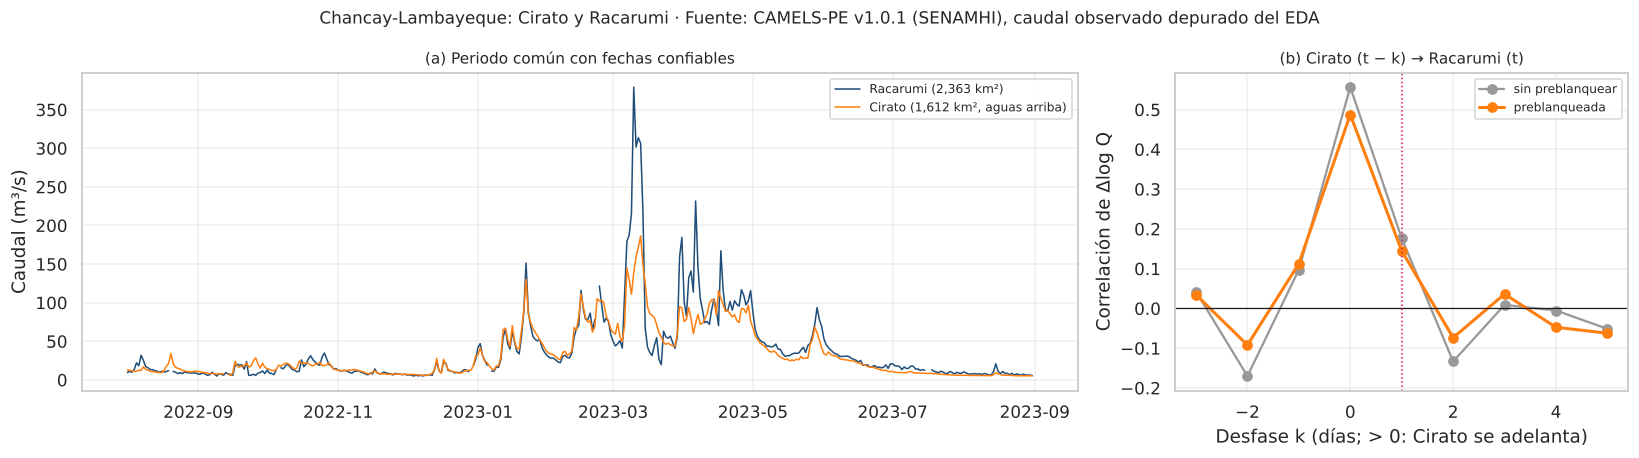

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={'width_ratios': [2.2, 1]})
ax[0].plot(qR.loc[D0:D1].index, qR.loc[D0:D1], color='#1f4e79', lw=1, label=f"Racarumi ({infoR['area']:,.0f} km²)")
ax[0].plot(qC.loc[D0:D1].index, qC.loc[D0:D1], color='#ff7f0e', lw=1, label=f"Cirato ({infoC['area']:,.0f} km², aguas arriba)")
ax[0].set_ylabel('Caudal (m³/s)'); ax[0].legend(fontsize=8); ax[0].grid(True, alpha=0.3)
ax[0].set_title('(a) Periodo común con fechas confiables', fontsize=10)
kk = ccf_rc.index
ax[1].plot(kk, ccf_rc['sin preblanquear'], 'o-', color='0.6', label='sin preblanquear')
ax[1].plot(kk, ccf_rc['preblanqueada'], 'o-', color='#ff7f0e', lw=2, label='preblanqueada')
ax[1].axhline(0, color='k', lw=0.8); ax[1].axvline(1, color='crimson', ls=':', lw=1)
ax[1].set_xlabel('Desfase k (días; > 0: Cirato se adelanta)'); ax[1].set_ylabel('Correlación de Δlog Q')
ax[1].set_title('(b) Cirato (t − k) → Racarumi (t)', fontsize=10); ax[1].legend(fontsize=8); ax[1].grid(True, alpha=0.3)
fig.suptitle('Chancay-Lambayeque: Cirato y Racarumi · ' + FUENTE, fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig06_racarumi_cirato.png', dpi=200, bbox_inches='tight'); plt.show()

---
## 11. Tabla maestra, salidas y resumen
Tabla maestra: una fila por configuración, modelo y periodo con su disponibilidad, NSE medio de selección y de prueba, horizonte útil y papel en las selecciones. Los pronósticos se guardan en `salidas/aguas_arriba/predicciones.npz` (el 07 y el 08 comprueban con él las emisiones; el 08 reutiliza los ajustes por la caché) y el resumen en `salidas/aguas_arriba/resumen.json`.

In [22]:
maestra = pm.merge(val[['conjunto', 'modelo', 'NSE medio selección']], on=['conjunto', 'modelo'])
maestra['seleccionado en su configuración de entradas (magnitud)'] = [SELM[next(k for k in SELM if I.etiqueta(*k) == r['conjunto'])] == r['modelo'] for _, r in maestra.iterrows()]
maestra['seleccionado en validación (periodo · escenario)'] = [', '.join(f'{per} · {esc}' for (per, esc), k in CONFIG.items()
                                                                     if I.nombre(k) == f"{r['conjunto']} · {r['modelo']}" and per.split(' (')[0] in r['periodo de prueba']) for _, r in maestra.iterrows()]
maestra.to_csv(RUTA_TAB / 'tabla_maestra.csv', index=False)
np.savez_compressed(RUTA_SAL / 'predicciones.npz', **I.claves_npz(x, P), **{'Tamshiyacu|fechas_pru_requena': x.m.fechas[IP_RQ].values.astype('datetime64[D]')})
resumen = {
    'version': C.VERSION, 'revision': C.REVISION, 'rapido': RAPIDO, 'etapa': 'caudal aguas arriba con los seis modelos (cuaderno 05)',
    'experimento': EN.VERSION_EXPERIMENTO, 'huella_codigo_ajuste': EN.huella_codigo(), 'P95': x.P95,
    'filas': {k: int(v) for k, v in div['emisiones'].items()},
    'transito_ccf': {f'{n} ({e})': int(tt.loc[(n, e), 'desfase del máximo (d)']) for n, e in tt.index},
    'conjuntos': [I.etiqueta(c, l) for c, l in CONJ],
    'modelo_seleccionado_por_conjunto': {I.etiqueta(*k): v for k, v in SELM.items()},
    'configuracion_seleccionada': {f'{per}|{esc}': I.nombre(k) for (per, esc), k in CONFIG.items()},
    'mayor_y_equivalentes': {f'{per}|{esc}': len(v) for (per, esc), v in EQUIV.items()},
    'inconclusos': {f'{per}|{esc}': len(NOPEOR[(per, esc)]) - len(v) for (per, esc), v in EQUIV.items()},
    'nse_medio_prueba': {f"{r['periodo de prueba']}|{r['conjunto']}|{r['modelo']}": round(float(r['NSE medio']), 4) for _, r in pm.iterrows()},
    'h_cota_prueba': {f"{r['periodo de prueba']}|{r['conjunto']}|{r['modelo']}": int(r['H cota 95 % (d)']) for _, r in pm.iterrows()},
    'cruces_evaluables': {k: {kk: (None if isinstance(vv, float) and not np.isfinite(vv) else vv) for kk, vv in v.items()} for k, v in cruces.to_dict('index').items()},
    'cirato': {f"{r['modo']}|h={r['h']}|{r['modelo']}": {'G': round(float(r['G frente a Q']), 3), 'lectura': r['lectura']}
               for _, r in cir[cir['conjunto'] == 'Q+C'].iterrows()},
    'cache': {'politica': 'solo identidad completa idéntica; sin migración', 'combinaciones': int(len(registro)), 'leidas_de_cache': int(registro['leído de la caché'].sum())},
    'minutos': round((time.time() - T_INICIO) / 60, 1),
}
(RUTA_SAL / 'resumen.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
print(json.dumps({k: resumen[k] for k in ['configuracion_seleccionada', 'cache', 'minutos']}, ensure_ascii=False, indent=1))
maestra[['periodo de prueba', 'conjunto', 'modelo', 'emisiones', 'NSE medio selección', 'NSE medio', 'H cota 95 % (d)',
         'seleccionado en validación (periodo · escenario)']].set_index(['periodo de prueba', 'conjunto', 'modelo']).round(3)

{
 "configuracion_seleccionada": {
  "con San Regis (prueba 2016-01 a 2025-12)|mismo día": "Q · KNN",
  "con San Regis (prueba 2016-01 a 2025-12)|un día de retraso": "Q · KNN",
  "común con Requena (prueba 2016-01 a 2020-03)|mismo día": "Q+SR · KNN",
  "común con Requena (prueba 2016-01 a 2020-03)|un día de retraso": "Q · KNN"
 },
 "cache": {
  "politica": "solo identidad completa idéntica; sin migración",
  "combinaciones": 42,
  "leidas_de_cache": 42
 },
 "minutos": 4.1
}


emisiones  \
periodo de prueba                            conjunto      modelo                        
con San Regis (prueba 2016-01 a 2025-12)     Q             Regresión lineal       2806   
                                                           Random Forest          2806   
                                                           XGBoost                2806   
                                                           KNN                    2806   
                                                           MLP                    2806   
                                                           LSTM                   2806   
                                             Q+SR          Regresión lineal       2806   
                                                           Random Forest          2806   
                                                           XGBoost                2806   
                                                           KNN                    2806   
                                                           MLP                    2806   
                                                           LSTM                   2806   
                                             Q+SR (t−1)    Regresión lineal       2806   
                                                           Random Forest          2806   
                                                           XGBoost                2806   
                                                           KNN                    2806   
                                                           MLP                    2806   
                                                           LSTM                   2806   
común con Requena (prueba 2016-01 a 2020-03) Q             Regresión lineal       1093   
                                                           Random Forest          1093   
                                                           XGBoost                1093   
                                                           KNN                    1093   
                                                           MLP                    1093   
                                                           LSTM                   1093   
                                             Q+SR          Regresión lineal       1093   
                                                           Random Forest          1093   
                                                           XGBoost                1093   
                                                           KNN                    1093   
                                                           MLP                    1093   
                                                           LSTM                   1093   
                                             Q+SR (t−1)    Regresión lineal       1093   
                                                           Random Forest          1093   
                                                           XGBoost                1093   
                                                           KNN                    1093   
                                                           MLP                    1093   
                                                           LSTM                   1093   
                                             Q+RQ          Regresión lineal       1093   
                                                           Random Forest          1093   
                                                           XGBoost                1093   
                                                           KNN                    1093   
                                                           MLP                    1093   
                                                           LSTM                   1093   
                                             Q+RQ (t−1)    Regresión lineal       1093   
                           

---
## 12. Conclusiones

1. **San Regis (Marañón) sí aporta al pronóstico de Tamshiyacu, con los seis modelos.**
   - **Desfase de máxima asociación de 1 día** (correlación preblanqueada máxima en k = 1, r = 0.34–0.37); con distancias y celeridades supuestas (1.5–2.3 m/s) es físicamente plausible, aunque no es una medición del tránsito.
   - Con el mismo modelo y las mismas emisiones, **reduce el error cuadrático 33–45 % a 1–3 días y 18–25 % a 4–7 días con los seis modelos** (prueba 2016-01 a 2025-12; IC 90 % > 0), y la validación lo había anticipado (25–37 % a 1–3 días).
   - **Con un día de retraso conserva 7–22 % a 1–3 días**: la mayor parte del aporte depende de tener el dato del mismo día.
2. **La selección para la magnitud elige Q · KNN en el periodo con San Regis.** La regla de selección del estudio compara el NSE medio de los 30 horizontes con un margen de ±0.01; la ganancia de San Regis se concentra en la primera semana y en ese promedio queda dentro del margen (Q · KNN 0.927 frente a Q+SR · KNN 0.929). En el periodo con Requena se elige Q+SR · KNN si las fuentes llegan el mismo día y Q · KNN con un día de retraso. En la prueba, el mayor NSE medio lo da el MLP con San Regis (0.913 en 2016-01 a 2025-12; 0.874 en el periodo con Requena), sin que eso cambie la selección. **La comparación con la lluvia y con Chronos-2, y la selección final del proyecto, están en el cuaderno 08.**
3. **Casi no cambia el horizonte útil** (0–3 días): en 2016-01 a 2025-12 ya es ≥ 30 días con los no lineales. **El efecto sobre los avisos de nuevos cruces no se puede evaluar** (3 cruces en la prueba, ninguno en el periodo con Requena); una mejora de la magnitud no basta para concluir que los días de aviso cambian.
4. **Requena (Ucayali): sin reducción demostrada del error con ninguno de los seis modelos salvo la LSTM a 1–3 días; con Random Forest y KNN lo aumenta a 1–3 días** (prueba común 2016-01 a 2020-03). Su desfase de máxima asociación no es positivo (máximo en k = −1) y sobre San Regis no agrega nada. El aporte de una estación depende del modelo y del periodo: con Chronos-2 se evalúa en el 07 y en el 08.
5. **Cirato: no se demostró una mejora con la muestra disponible**, con ninguno de los seis modelos, en modo retrospectivo ni prospectivo. El desfase de máxima asociación es 0 días y hay solo 13 meses con fechas confiables. Con tan pocos datos esto no demuestra que Cirato no aporte.
6. **Para la pregunta del proyecto:** la estación aguas arriba inmediata útil es San Regis, y lo es para la **magnitud** de corto plazo en Tamshiyacu. Para buscar más anticipación habría que mirar **más arriba** en la red (por ejemplo, Borja en el Marañón o Pucallpa en el Ucayali) o usar datos con resolución menor a un día en el Chancay-Lambayeque, y evaluarla con eventos.

### Limitaciones
- **Disponibilidad operativa:** el escenario «mismo día» supone que el caudal de San Regis del día t está disponible al emitir; no está demostrado. En 2019 San Regis y Requena dejaron de tener dato justo al inicio de la crecida (vacíos de 147 y 180 días). Un sistema que dependa de ellas debe prever qué hacer cuando faltan, justo cuando más se necesitan.
- **Prueba común con Requena corta y sin eventos:** 1 093 emisiones de 2016-01 a 2020-03, sin días sobre el P95. Las conclusiones sobre crecidas se apoyan en la prueba con San Regis (3 eventos, descriptivo).
- **Entrenamiento más corto que en el cuaderno 02** (1998–2008, 2 847 emisiones), impuesto por el inicio de San Regis y la exigencia de Requena válida en entrenamiento y validación.
- **Regla de selección:** el NSE medio de 30 horizontes con margen ±0.01 es la regla fijada antes de ejecutar; no premia una ganancia concentrada en los primeros días. Se informa la ganancia por bandas sin cambiar la regla.
- **Escalones de nivel en San Regis** (17, casi todos antes de 2015): se excluyen las ventanas que los cruzan, pero el nivel de los bloques entre escalones no se puede verificar (EDA 2.7).
- **Requena:** termina en 2020-03, y su desfase no positivo respecto a Tamshiyacu contradice lo esperado por distancia. No se puede separar un efecto hidráulico (remanso, llanura de inundación) de un problema de fechas.
- **Cirato:** 13 meses y un solo periodo de lluvias; hiperparámetros fijos, sin selección; resultado exploratorio. No se usó el tramo con fechas corridas ni el caudal simulado (sección 0.2).
- **Uso previo de la prueba:** el periodo de prueba (desde 2016-01) se consultó con estas estaciones durante el desarrollo del proyecto. Las reglas se fijaron antes de la evaluación final, pero no es una prueba ciega.